# SEVIRI Rapid Scan data: preview and 2024 download test

This notebook has two different satellite workflows:

1. **Quick preview:** request a current rendered image from EUMETSAT WMS. This is a visualization, not raw measurements and not the January 2024 scene.
2. **Historical data test:** find the two 5-minute RSS products around 1 January 2024 12:00 UTC, optionally download one original product, and ask Data Tailor to crop both products to the GB bounding box and convert the 11 non-HRV channels to NetCDF4.

The final figure plots stored values from the tailored NetCDF files as a spatial sanity check. This first test is local only. Keep original EUMETSAT data out of Git and shared services; attribute derived figures as **Contains modified EUMETSAT Meteosat data, 2024.**

TODO (per Luke):
- make it so that you don't need to input credentials every time (since it seems my user creds are static anyways)
- check to see what downloads exist before attempting to download content that is already present on disc
- Be careful with "GB" titles for maps that also includes NI or other regions

In [37]:
# ========================= USER OPTIONS =========================
# Change the values in this cell before running the cells below.
#
# Preview layers are WMS visualizations. Choose exactly one preview layer for
# the map image. The strings below come from EUMETSAT's live WMS
# GetCapabilities response for the `msg_rss` workspace.
PREVIEW_LAYERS = {
    "ir039_nrt": "Rapid Scan High Rate SEVIRI IR 3.9",
    "rgb_microphysics_nrt": "Rapid Scan High Rate SEVIRI RGB Day Microphysics",
    "rgb_natural_nrt": "Rapid Scan High Rate SEVIRI RGB Natural Colour",
    "rgb_naturalenhncd_nrt": "Rapid Scan High Rate SEVIRI RGB Natural Colour Enhanced",
}

# Select one of the preview layer IDs above. To try another visualization,
# comment out the current assignment and uncomment a different one.
# SELECTED_PREVIEW_LAYER = "ir039_nrt"
# SELECTED_PREVIEW_LAYER = "rgb_microphysics_nrt"
# SELECTED_PREVIEW_LAYER = "rgb_natural_nrt"
SELECTED_PREVIEW_LAYER = "rgb_naturalenhncd_nrt"

# These are the underlying SEVIRI data channels, as named by EUMETSAT in the
# HRSEVIRI/HRSEVIRI_RSS numerical product. They are NOT WMS preview layers.
# The list below is what we would select later when downloading raw numerical
# data through the EUMETSAT Data Store/Data Tailor.
SEVIRI_DATA_CHANNELS = {
    "channel_1": "VIS0.6 (visible light)",
    "channel_2": "VIS0.8 (visible light)",
    "channel_3": "NIR1.6 (near infrared)",
    "channel_4": "IR3.9 (infrared)",
    "channel_5": "WV6.2 (water vapour)",
    "channel_6": "WV7.3 (water vapour)",
    "channel_7": "IR8.7 (infrared)",
    "channel_8": "IR9.7 (infrared)",
    "channel_9": "IR10.8 (infrared)",
    "channel_10": "IR12.0 (infrared)",
    "channel_11": "IR13.4 (infrared)",
    "hrv": "High Resolution Visible channel",
}

# Select the raw channels you want to request. The default matches OCF's
# PVNet example: all 11 non-HRV channels. To include HRV later, change
# INCLUDE_HRV to True; SELECTED_DATA_CHANNELS is built automatically.
INCLUDE_HRV = False
SELECTED_DATA_CHANNELS = list(SEVIRI_DATA_CHANNELS)
if not INCLUDE_HRV:
    SELECTED_DATA_CHANNELS.remove("hrv")

if SELECTED_PREVIEW_LAYER not in PREVIEW_LAYERS:
    raise ValueError(f"Unknown preview layer: {SELECTED_PREVIEW_LAYER}")
unknown_channels = set(SELECTED_DATA_CHANNELS) - set(SEVIRI_DATA_CHANNELS)
if unknown_channels:
    raise ValueError(f"Unknown SEVIRI data channels: {sorted(unknown_channels)}")

print(f"Selected WMS preview: {SELECTED_PREVIEW_LAYER} ({PREVIEW_LAYERS[SELECTED_PREVIEW_LAYER]})")
print("Selected raw data channels for a future Data Store download:")
for channel in SELECTED_DATA_CHANNELS:
    print(f"- {channel}: {SEVIRI_DATA_CHANNELS[channel]}")

Selected WMS preview: rgb_naturalenhncd_nrt (Rapid Scan High Rate SEVIRI RGB Natural Colour Enhanced)
Selected raw data channels for a future Data Store download:
- channel_1: VIS0.6 (visible light)
- channel_2: VIS0.8 (visible light)
- channel_3: NIR1.6 (near infrared)
- channel_4: IR3.9 (infrared)
- channel_5: WV6.2 (water vapour)
- channel_6: WV7.3 (water vapour)
- channel_7: IR8.7 (infrared)
- channel_8: IR9.7 (infrared)
- channel_9: IR10.8 (infrared)
- channel_10: IR12.0 (infrared)
- channel_11: IR13.4 (infrared)


## 1. Quick visual preview (current imagery)

Choose a WMS layer in **USER OPTIONS**, then run this cell for the latest available rendered preview. The preview is live/current imagery; it does not show the historical 2024 downloads below.

Latest Rapid Scan High Rate SEVIRI RGB Natural Colour Enhanced time: 2026-10-30T11:20:00.000Z


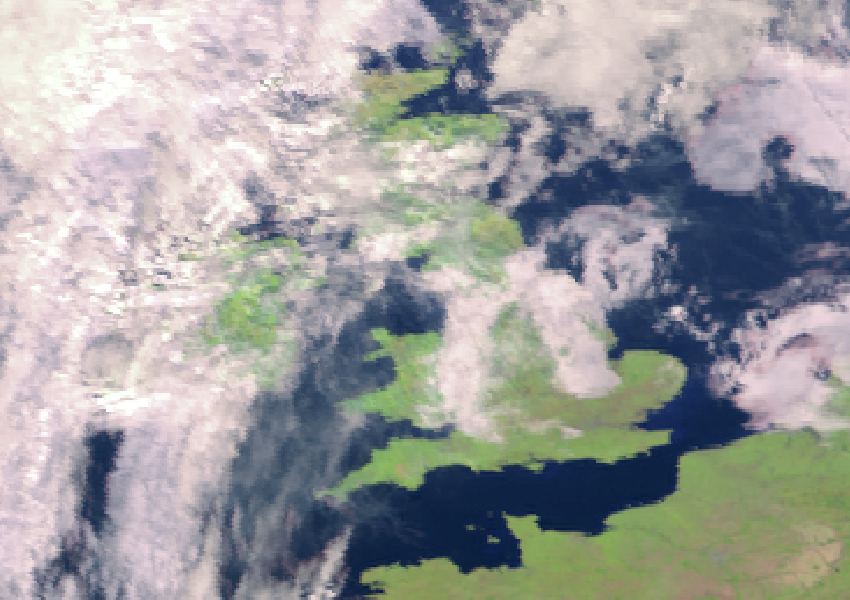

In [38]:
# ElementTree is part of Python and lets us read the XML document that describes
# the WMS service. `requests` sends ordinary web requests; no API key is needed
# for this public rendered-image service.
import xml.etree.ElementTree as ET

import requests
from IPython.display import Image, display

# These URLs come from the EUMETSAT EUMETView product page. The selected layer
# is inserted into the layer-specific GetCapabilities URL below. The base WMS
# URL is used for the later GetMap request that actually renders the image.
# Product page: https://view.eumetsat.int/productviewer/productDetails/msg_rss:ir039_nrt
capabilities_url = f"https://view.eumetsat.int/geoserver/msg_rss/{SELECTED_PREVIEW_LAYER}/ows"
wms_base_url = "https://view.eumetsat.int/geoserver/ows"

# Ask the server for the selected preview layer's capabilities document.
# `params` becomes the query string after the `?` in the URL. WMS is the
# service, GetCapabilities is the operation, and version selects the protocol.
capabilities_response = requests.get(
    capabilities_url,
    params={"service": "WMS", "request": "GetCapabilities", "version": "1.3.0"},
    timeout=30,
)
capabilities_response.raise_for_status()

# The response is XML. XML elements have a namespace (like a vocabulary),
# so include it when searching for WMS elements such as <Layer> and <Dimension>.
wms_namespace = {"wms": "http://www.opengis.net/wms"}
capabilities = ET.fromstring(capabilities_response.content)

# Find the selected layer by its short name. The full WMS layer name used by
# GetMap is `msg_rss:<selected layer>`, where `msg_rss` is the workspace.
rss_layer = next(
    layer
    for layer in capabilities.findall(".//wms:Layer", wms_namespace)
    if layer.findtext("wms:Name", namespaces=wms_namespace) == SELECTED_PREVIEW_LAYER
)

# The layer advertises its time coverage as start/end/step, for example
# start/latest/PT5M. PT5M means a five-minute interval. Use the end of that
# range so this notebook follows the newest time currently published by EUMETSAT.
time_dimension = next(
    dimension
    for dimension in rss_layer.findall("wms:Dimension", wms_namespace)
    if dimension.attrib.get("name") == "time"
)
time_extent = time_dimension.text.strip().split("/")
latest_time = time_extent[1]

# GetMap asks WMS to render the selected preview layer as an image. This is a
# visualization, not the raw numerical satellite measurements listed in the
# configuration cell. The bbox is in WMS 1.3.0 EPSG:4326 axis order:
# south latitude, west longitude, north latitude, east longitude.
map_response = requests.get(
    wms_base_url,
    params={
        "service": "WMS",
        "request": "GetMap",
        "version": "1.3.0",
        "layers": f"msg_rss:{SELECTED_PREVIEW_LAYER}",
        "styles": "",  # Empty means use the server's default layer style.
        "format": "image/png",
        "crs": "EPSG:4326",  # Geographic latitude/longitude coordinates.
        "bbox": "48,-12,60,5",
        "width": 850,
        "height": 600,
        "time": latest_time,
    },
    timeout=60,
)
map_response.raise_for_status()

# A successful HTTP response might still contain an XML error message, so check
# that the server really returned a PNG before asking Jupyter to display it.
content_type = map_response.headers.get("Content-Type", "")
if not content_type.startswith("image/png"):
    raise ValueError(f"Expected a PNG map, received {content_type}")

print(f"Latest {PREVIEW_LAYERS[SELECTED_PREVIEW_LAYER]} time: {latest_time}")
display(Image(data=map_response.content))

### Optional: overlay local administrative boundaries

The next cell uses a local GeoJSON folder path specific to this computer. Skip it if those files are unavailable; the WMS preview above does not depend on them.

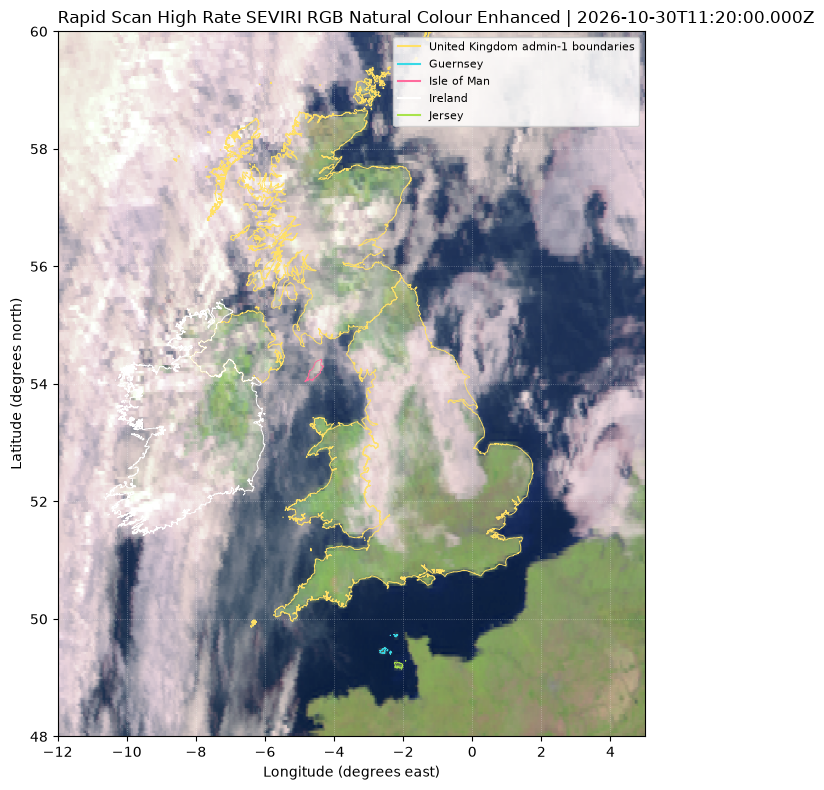

In [39]:
# json reads the boundary files; BytesIO lets Matplotlib read the PNG bytes
# already held in memory; Path makes it easier to work with file locations.
import json
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# These GeoJSON files live in a separate local project. If you move this
# notebook or the data, change this path to the folder containing the files.
boundary_directory = Path(
    "/Users/mans5211/GitHub-repos/Met-Office-Solar-Luke/data/inputs/boundaries"
)
boundary_files = sorted(boundary_directory.glob("gadm41_*.json"))
if not boundary_files:
    raise FileNotFoundError(f"No GADM GeoJSON files found in {boundary_directory}")

# Give each boundary dataset a distinct visible color on top of the satellite image.
boundary_colors = ["#ffe066", "#38d9e6", "#ff6b9d", "#ffffff", "#a9e34b"]
if len(boundary_files) > len(boundary_colors):
    raise ValueError("Add more boundary colors before plotting the additional files.")

# Start a Matplotlib figure. `axis` is the area where the map, borders, labels,
# and grid will be drawn.
figure, axis = plt.subplots(figsize=(10, 8))

# Place the WMS PNG in geographic space. `extent` is (west, east, south, north)
# in longitude/latitude degrees, matching the UK bbox requested above.
satellite_image = plt.imread(BytesIO(map_response.content))
axis.imshow(
    satellite_image,
    extent=(-12, 5, 48, 60),
    origin="upper",
)

# Create one legend entry per GeoJSON file. A file can contain many separate
# polygons, so adding every line to the legend would make it unreadable.
legend_handles = []
for boundary_file, color in zip(boundary_files, boundary_colors):
    # The supplied GeoJSON files use CRS84 coordinates: [longitude, latitude].
    with boundary_file.open() as file:
        boundary_data = json.load(file)

    if boundary_file.stem == "gadm41_GBR_1":
        label = "United Kingdom admin-1 boundaries"
    else:
        country_name = boundary_data["features"][0]["properties"]["COUNTRY"]
        label = {"IsleofMan": "Isle of Man"}.get(country_name, country_name)

    # GeoJSON can store a Polygon or a MultiPolygon. Both contain nested rings
    # of [longitude, latitude] points, which Matplotlib can draw as lines.
    for feature in boundary_data["features"]:
        geometry = feature["geometry"]
        if geometry["type"] == "Polygon":
            polygons = [geometry["coordinates"]]
        elif geometry["type"] == "MultiPolygon":
            polygons = geometry["coordinates"]
        else:
            continue

        for polygon in polygons:
            for ring in polygon:
                longitudes = [point[0] for point in ring]
                latitudes = [point[1] for point in ring]
                axis.plot(longitudes, latitudes, color=color, linewidth=0.65)

    legend_handles.append(Line2D([0], [0], color=color, lw=1.5, label=label))

# Set the geographic window and add map labels. The aspect adjustment accounts
# for longitude degrees being narrower than latitude degrees at UK latitudes.
axis.set_xlim(-12, 5)
axis.set_ylim(48, 60)
axis.set_aspect(1.0 / 0.588)
axis.set_xlabel("Longitude (degrees east)")
axis.set_ylabel("Latitude (degrees north)")
axis.set_title(f"{PREVIEW_LAYERS[SELECTED_PREVIEW_LAYER]} | {latest_time}", loc="left")
axis.grid(color="white", alpha=0.35, linestyle=":", linewidth=0.6)
axis.legend(handles=legend_handles, loc="upper right", framealpha=0.8, fontsize=8)

figure.tight_layout()
display(figure)
plt.close(figure)

## 2. Find the two historical RSS products

The search window is 12:00–12:06 UTC on 1 January 2024. RSS scans arrive every five minutes. Product IDs end with the sensing end time, so the scan covering approximately 12:00–12:04 is named `...120417...`, and the next scan ends around `...120917...`.

The notebook reads credentials from `EUMETSAT_CONSUMER_KEY` and `EUMETSAT_CONSUMER_SECRET`, or requests them with secure input prompts. Do not put credentials in notebook source or output.

In [40]:
# EUMDAC is EUMETSAT's official Python client for searching and downloading
# Data Store products. It was installed into this notebook's kernel separately.
import datetime as dt
import getpass
import os
from pathlib import Path

import eumdac

RSS_COLLECTION_ID = "EO:EUM:DAT:MSG:MSG15-RSS"
SEARCH_START_UTC = dt.datetime(2024, 1, 1, 12, 0, 0)
SEARCH_END_UTC = dt.datetime(2024, 1, 1, 12, 6, 0)
GB_BBOX_WSEN = (-8.0, 49.8, 2.0, 61.2)
# Data Tailor requires NSWE to be a list: north, south, west, east.
GB_ROI_NSWE = {"NSWE": [61.2, 49.8, -8.0, 2.0]}
RUN_DATA_TAILOR = True
RAW_OUTPUT_DIRECTORY = Path("data/satellite/rss_2024_test")

# If VS Code inherited the terminal variables, use them. Otherwise, getpass
# opens the secure input popup at the top of the VS Code window. Enter one
# credential per popup and press Enter; do not type either credential in chat.
consumer_key = os.getenv("EUMETSAT_CONSUMER_KEY")
consumer_secret = os.getenv("EUMETSAT_CONSUMER_SECRET")
if not consumer_key:
    consumer_key = getpass.getpass("EUMETSAT Consumer Key: ")
if not consumer_secret:
    consumer_secret = getpass.getpass("EUMETSAT Consumer Secret: ")

if not consumer_key or not consumer_secret:
    raise ValueError("Both EUMETSAT credentials are required to search the Data Store.")

token = eumdac.AccessToken((consumer_key, consumer_secret))
datastore = eumdac.DataStore(token)
rss_collection = datastore.get_collection(RSS_COLLECTION_ID)
rss_products = list(
    rss_collection.search(
        dtstart=SEARCH_START_UTC,
        dtend=SEARCH_END_UTC,
        bbox=", ".join(str(value) for value in GB_BBOX_WSEN),
        set="brief",
    )
)

print(f"Found {len(rss_products)} RSS products:")
for product in rss_products:
    print(product)

if RUN_DATA_TAILOR:
    RAW_OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    print(f"Download directory: {RAW_OUTPUT_DIRECTORY.resolve()}")

Found 2 RSS products:
MSG4-SEVI-MSG15-0100-NA-20240101120917.658000000Z-NA
MSG4-SEVI-MSG15-0100-NA-20240101120417.851000000Z-NA
Download directory: /Users/mans5211/GitHub-repos/PVNet/Luke/data/satellite/rss_2024_test


In [41]:
# Refresh the EUMETSAT token before retrying Data Tailor.
token = eumdac.AccessToken((consumer_key, consumer_secret), validity=3600, cache=False)
datastore = eumdac.DataStore(token)
print("Fresh EUMETSAT token created.")

Fresh EUMETSAT token created.


In [ ]:
# Data Tailor needs NSWE as four numeric values: north, south, west, east.
# The Data Store search API above uses a separate WSEN bounding box.
GB_ROI_NSWE = {"NSWE": [61.2, 49.8, -8.0, 2.0]}
print("Data Tailor ROI (N, S, W, E):", GB_ROI_NSWE)

## 3. Optional: download one original source product

This EUMDAC step downloads one full original product as a ZIP. It does not crop to GB or select channels, so it is substantially larger than the tailored outputs. It is useful for checking direct Data Store access independently of Data Tailor. Set `DIRECT_DOWNLOAD_PRODUCT_INDEX` to `0` or `1` in the cell to choose the product.

In [43]:
# Direct source-product download diagnostic (bypasses Data Tailor).
import shutil
import time
import zipfile

if not rss_products:
    raise RuntimeError("No products are available. Run the search cell first.")

# Set this to 0 or 1 to choose one of the two products returned by the search.
DIRECT_DOWNLOAD_PRODUCT_INDEX = 0
if not 0 <= DIRECT_DOWNLOAD_PRODUCT_INDEX < len(rss_products):
    raise IndexError(
        f"DIRECT_DOWNLOAD_PRODUCT_INDEX must be from 0 to {len(rss_products) - 1}."
    )

direct_product = rss_products[DIRECT_DOWNLOAD_PRODUCT_INDEX]
DIRECT_DOWNLOAD_DIRECTORY = RAW_OUTPUT_DIRECTORY / "original_products"
DIRECT_DOWNLOAD_DIRECTORY.mkdir(parents=True, exist_ok=True)
direct_archive = DIRECT_DOWNLOAD_DIRECTORY / f"{direct_product}.zip"
direct_started = time.perf_counter()

if direct_archive.exists() and direct_archive.stat().st_size > 0:
    print(f"Using existing archive: {direct_archive} ({direct_archive.stat().st_size:,} bytes)")
else:
    partial_archive = direct_archive.with_suffix(".zip.part")
    print(f"Downloading original product directly: {direct_product}")
    try:
        with direct_product.open() as source, partial_archive.open("wb") as target:
            shutil.copyfileobj(source, target)
        partial_archive.replace(direct_archive)
    except Exception:
        partial_archive.unlink(missing_ok=True)
        raise
    print(f"Saved: {direct_archive} ({direct_archive.stat().st_size:,} bytes)")

# Validate the archive without extracting it, and show the packaged files.
with zipfile.ZipFile(direct_archive) as archive:
    bad_member = archive.testzip()
    if bad_member is not None:
        raise RuntimeError(f"ZIP integrity check failed at: {bad_member}")
    archive_entries = archive.infolist()

print(f"ZIP integrity: OK ({len(archive_entries)} entries)")
for entry in archive_entries:
    print(f"- {entry.filename} ({entry.file_size:,} bytes uncompressed)")
print(f"Direct download and validation elapsed: {time.perf_counter() - direct_started:.1f} seconds")

Using existing archive: data/satellite/rss_2024_test/original_products/MSG4-SEVI-MSG15-0100-NA-20240101120917.658000000Z-NA.zip (58,627,343 bytes)
ZIP integrity: OK (3 entries)
- EOPMetadata.xml (4,683 bytes uncompressed)
- MSG4-SEVI-MSG15-0100-NA-20240101120917.658000000Z-NA.nat (102,210,123 bytes uncompressed)
- manifest.xml (556 bytes uncompressed)
Direct download and validation elapsed: 0.1 seconds


## 4. Tailor both products to GB and NetCDF4

Data Tailor processes each source product separately, selecting the 11 non-HRV channels and applying the GB bounding box. The archives are saved under `RAW_OUTPUT_DIRECTORY`. The cell reports elapsed time per product and overall. Set `RUN_DATA_TAILOR = False` in the search/setup cell to skip job submission.

Use this dataset under the delayed Meteosat licence: cite EUMETSAT, do not redistribute the original numerical data, and do not use it operationally or commercially.

In [44]:
# This cell is deliberately gated. It will not submit any Data Tailor jobs
# unless RUN_DATA_TAILOR=True in the setup cell.
import fnmatch
import shutil
import time

if not RUN_DATA_TAILOR:
    print("Data Tailor is disabled. Set RUN_DATA_TAILOR=True to submit the jobs.")
elif not rss_products:
    raise RuntimeError("No RSS products are available to download.")
else:
    # Data Tailor receives the product type plus instructions for the output.
    # `netcdf4` keeps the scientific values in a machine-readable format.
    # `bands` selects the 11 non-HRV channels from the top configuration cell.
    # Data Tailor's service requires NSWE as a list of four coordinates.
    data_tailor = eumdac.DataTailor(token)
    chain = eumdac.tailor_models.Chain(
        product="HRSEVIRI",
        format="netcdf4",
        filter={"bands": SELECTED_DATA_CHANNELS},
        projection="geographic",
        # Geographic target resolutions are in degrees: ~3 km in both directions over GB.
        resample_method="bilinear",
        resample_resolution=[0.05, 0.03],  # X (longitude), Y (latitude)
        roi=GB_ROI_NSWE,
        compression={"format": "zip"},
    )

    batch_started = time.perf_counter()
    for product in rss_products:
        product_started = time.perf_counter()
        print(f"Submitting Data Tailor job for {product}...")
        customisation = data_tailor.new_customisation(product, chain=chain)

        # Data Tailor processing is asynchronous. Poll until the server has
        # finished, then stream the result to the local output directory.
        while True:
            status = customisation.status
            print(f"  status: {status}")
            if status == "DONE":
                break
            if status in {"ERROR", "FAILED", "KILLED", "DELETED", "INACTIVE"}:
                raise RuntimeError(f"Data Tailor failed for {product}: {customisation.logfile}")
            time.sleep(10)

        output_files = fnmatch.filter(customisation.outputs, "*")
        for output_file in output_files:
            destination = RAW_OUTPUT_DIRECTORY / Path(output_file).name
            with customisation.stream_output(output_file) as source, destination.open("wb") as target:
                shutil.copyfileobj(source, target)
            print(f"  saved: {destination}")

        # Remove the finished server-side customisation after downloading it.
        customisation.delete()
        print(f"  elapsed for this product: {time.perf_counter() - product_started:.1f} seconds")

    print(f"Total Data Tailor elapsed: {time.perf_counter() - batch_started:.1f} seconds")

print("Data Tailor step finished.")

Submitting Data Tailor job for MSG4-SEVI-MSG15-0100-NA-20240101120917.658000000Z-NA...
  status: DONE
  saved: data/satellite/rss_2024_test/HRSEVIRI_20240101T120510Z_20240101T120917Z_epct_e0bfbebc_FPRC.zip
  elapsed for this product: 81.9 seconds
Submitting Data Tailor job for MSG4-SEVI-MSG15-0100-NA-20240101120417.851000000Z-NA...
  status: RUNNING
  status: DONE
  saved: data/satellite/rss_2024_test/HRSEVIRI_20240101T120010Z_20240101T120417Z_epct_b05c3d72_FPRC.zip
  elapsed for this product: 91.2 seconds
Total Data Tailor elapsed: 173.2 seconds
Data Tailor step finished.


## 5. Visualize the tailored measurements

The figure reads the NetCDF files inside the Data Tailor ZIP archives and plots VIS 0.6 μm (`channel_1`) and IR 10.8 μm (`channel_9`) for each timestamp. The color scale shows the values stored in the NetCDF; this is a spatial sanity check, not a calibrated reflectance or brightness-temperature visualization.

Found 4 tailored files; plotting the first two in timestamp order.


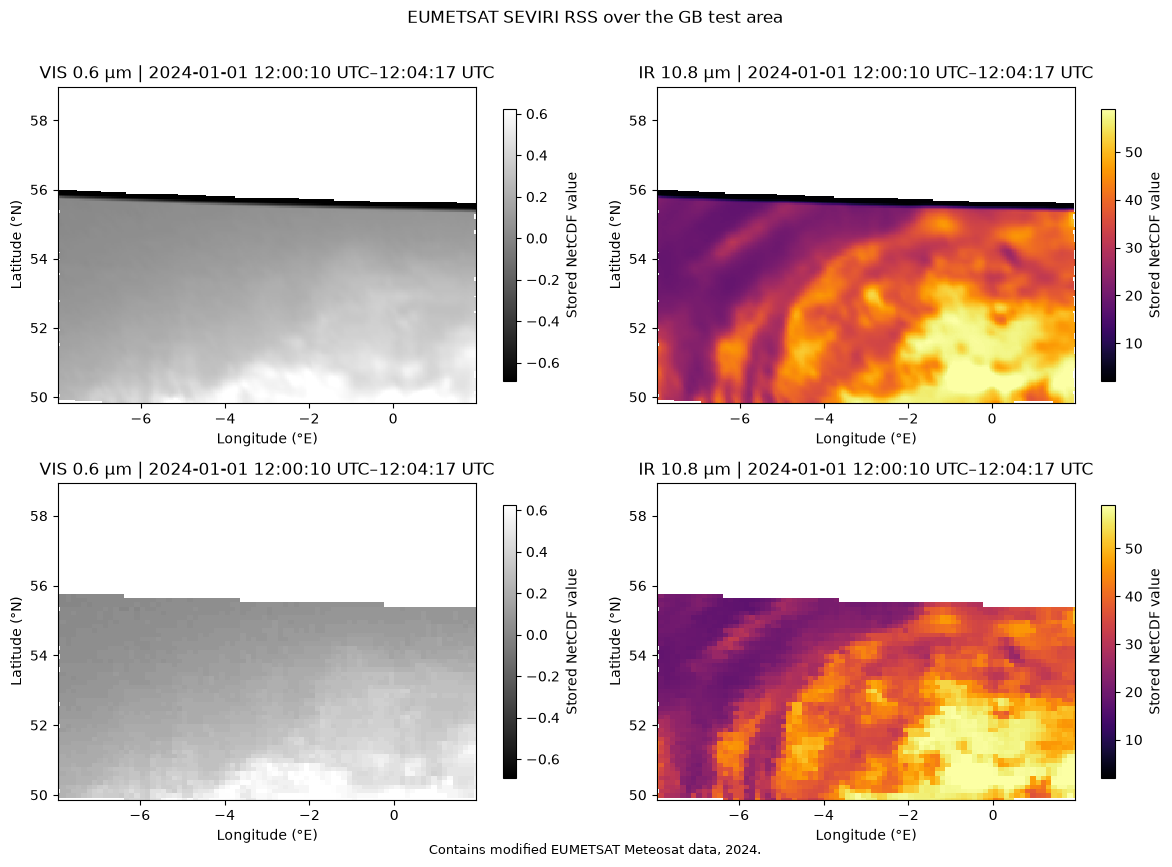

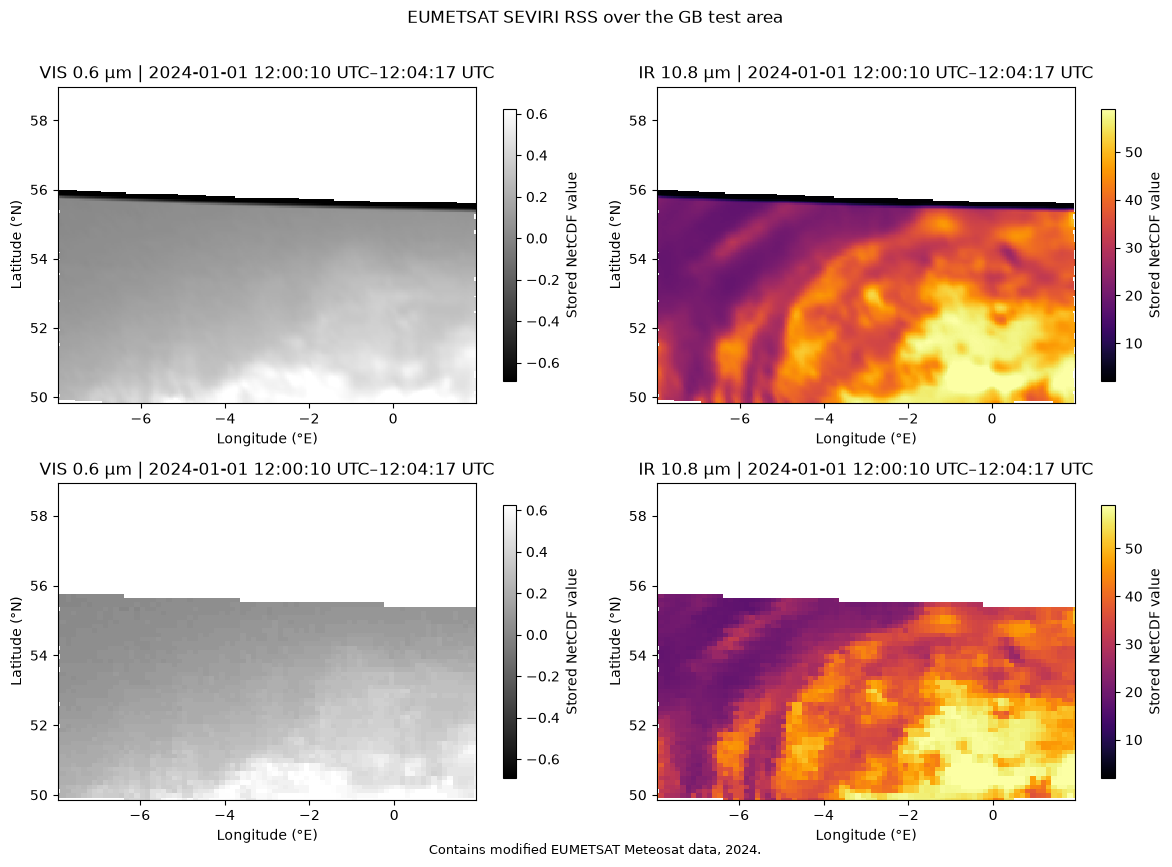

In [45]:
from datetime import datetime
from io import BytesIO
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# Read the small tailored NetCDF files directly from their ZIPs; no extraction needed.
tailored_archives = sorted(RAW_OUTPUT_DIRECTORY.glob("HRSEVIRI_*.zip"))
if not tailored_archives:
    raise FileNotFoundError(
        f"No tailored HRSEVIRI ZIPs found in {RAW_OUTPUT_DIRECTORY}. Run the Data Tailor cell first."
    )

snapshots = []
for archive_path in tailored_archives:
    with zipfile.ZipFile(archive_path) as archive:
        netcdf_members = [name for name in archive.namelist() if name.lower().endswith((".nc", ".nc4"))]
        if len(netcdf_members) != 1:
            raise ValueError(f"Expected one NetCDF file in {archive_path.name}; found {netcdf_members}")
        with xr.open_dataset(BytesIO(archive.read(netcdf_members[0])), engine="h5netcdf") as dataset:
            start = dataset.attrs.get("EPCT_start_sensing_time", archive_path.stem)
            stop = dataset.attrs.get("EPCT_stop_sensing_time", "")
            if stop:
                start_label = datetime.strptime(start, "%Y%m%dT%H%M%SZ").strftime("%Y-%m-%d %H:%M:%S UTC")
                stop_label = datetime.strptime(stop, "%Y%m%dT%H%M%SZ").strftime("%H:%M:%S UTC")
                snapshot_label = f"{start_label}–{stop_label}"
            else:
                snapshot_label = str(start)
            channel_values = {}
            for channel, calibration_attribute in (("channel_1", "ch01_cal"), ("channel_9", "ch09_cal")):
                values = dataset[channel].values.copy()
                # Data Tailor encodes out-of-scan zero counts at the channel calibration offset.
                offset = float(dataset.attrs[calibration_attribute].split()[0])
                channel_values[channel] = np.where(np.isclose(values, offset, atol=1e-6), np.nan, values)
            snapshots.append({
                "label": snapshot_label,
                "lat": dataset["lat"].values,
                "lon": dataset["lon"].values,
                **channel_values,
            })

if len(snapshots) > 2:
    print(f"Found {len(snapshots)} tailored files; plotting the first two in timestamp order.")
snapshots = snapshots[:2]
channels = [
    ("channel_1", "VIS 0.6 μm", "gray"),
    ("channel_9", "IR 10.8 μm", "inferno"),
]

fig, axes = plt.subplots(len(snapshots), len(channels), figsize=(12, 4.2 * len(snapshots)), squeeze=False)
for column, (channel, title, cmap) in enumerate(channels):
    finite_values = np.concatenate([
        snapshot[channel][np.isfinite(snapshot[channel])].ravel() for snapshot in snapshots
    ])
    vmin, vmax = np.nanpercentile(finite_values, [2, 98])
    for row, snapshot in enumerate(snapshots):
        ax = axes[row, column]
        mesh = ax.pcolormesh(
            snapshot["lon"], snapshot["lat"], snapshot[channel],
            shading="auto", cmap=cmap, vmin=vmin, vmax=vmax,
        )
        ax.set_title(f"{title} | {snapshot['label']}")
        ax.set_xlabel("Longitude (°E)")
        ax.set_ylabel("Latitude (°N)")
        ax.set_xlim(float(snapshot["lon"].min()), float(snapshot["lon"].max()))
        ax.set_ylim(float(snapshot["lat"].min()), float(snapshot["lat"].max()))
        fig.colorbar(mesh, ax=ax, label="Stored NetCDF value", shrink=0.86)

fig.suptitle("EUMETSAT SEVIRI RSS over the GB test area", y=1.01)
fig.text(0.5, 0.005, "Contains modified EUMETSAT Meteosat data, 2024.", ha="center", fontsize=9)
fig.tight_layout()
fig

## 6. Natural-colour RGB with full GB borders (additional view)

This separate figure uses NIR 1.6 μm (`channel_3`) in red, VIS 0.8 μm (`channel_2`) in green, and VIS 0.6 μm (`channel_1`) in blue, following EUMETSAT's natural-colour channel combination. Each band is contrast-stretched for display, so this remains a pseudo-natural-colour image rather than a calibrated photograph. The complete Great Britain admin-1 boundaries come from local GADM v4.1 data.

**The ROI is now expanded north to 61.2°N** so it includes the Shetland Islands and the full north of Scotland. The tailored files currently saved on disk were created with the old 59.0°N limit and default 0.125° resolution; rerun the search/setup and Data Tailor cells before this figure to create the expanded, higher-resolution crop. The new chain requests 0.05° longitude × 0.03° latitude (about 3 km) with bilinear resampling. The plotting code selects the newest tailored ZIP for each timestamp.

The current WMS preview is live imagery from 2026, while this composite is from 1 January 2024. Also, WMS's “Natural Colour Enhanced” layer is rendered and enhanced by EUMETSAT; this figure uses the tailored channel values with a simple display stretch, so expect different colours and cloud patterns.

Gray pixels mark invalid/out-of-scan channel values. EUMETSAT describes RSS as covering approximately 15°–70°N ([MSG SEVIRI Level 1.5 guide](https://user.eumetsat.int/resources/user-guides/msg-high-rate-seviri-level-1-5-data-guide)). In the currently saved 2024 outputs, valid pixels stop near 55.8°N despite the requested grid extending north; the larger ROI will show whether this persists. The earlier manual download is the same `120417` source product as the first tailored image, according to its metadata.

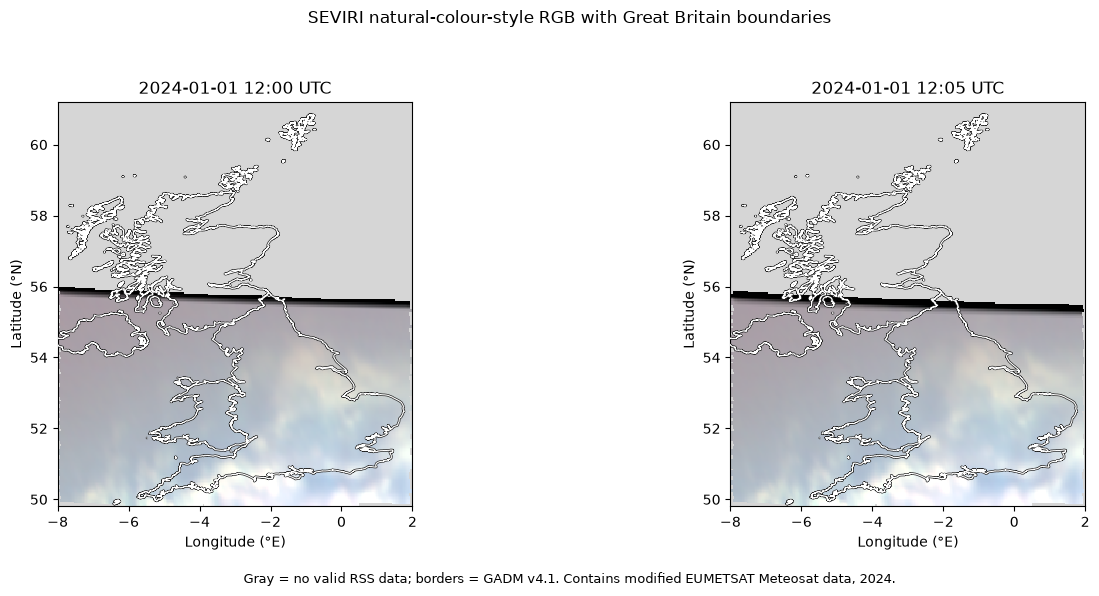

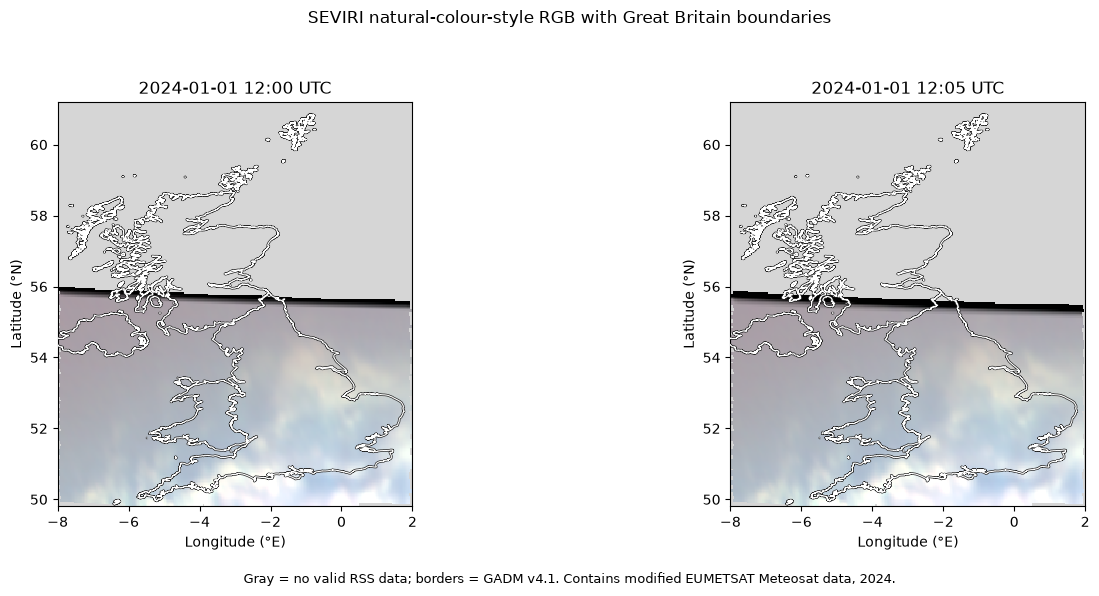

In [46]:
# Create a natural-colour-style RGB from the 3 daylight channels and overlay GB admin-1 borders.
import json
import zipfile
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import xarray as xr

GB_BOUNDARY_FILE = Path(
    "/Users/mans5211/GitHub-repos/Met-Office-Solar-Luke/data/inputs/boundaries/gadm41_GBR_1.json"
)
if not GB_BOUNDARY_FILE.exists():
    raise FileNotFoundError(
        f"GB boundary file not found at {GB_BOUNDARY_FILE}; update GB_BOUNDARY_FILE to your GADM v4.1 file."
    )

archive_candidates = list(RAW_OUTPUT_DIRECTORY.glob("HRSEVIRI_*.zip"))
# If a crop is re-run, several archives may exist for each timestamp. Keep the newest per scan.
newest_by_scan = {}
for candidate in archive_candidates:
    scan_key = candidate.name.split("_epct_")[0]
    if scan_key not in newest_by_scan or candidate.stat().st_mtime > newest_by_scan[scan_key].stat().st_mtime:
        newest_by_scan[scan_key] = candidate
rgb_archives = [newest_by_scan[key] for key in sorted(newest_by_scan)]
if not rgb_archives:
    raise FileNotFoundError(f"No tailored HRSEVIRI ZIPs found in {RAW_OUTPUT_DIRECTORY}.")

rgb_snapshots = []
for archive_path in rgb_archives[:2]:
    with zipfile.ZipFile(archive_path) as archive:
        nc_member = next(name for name in archive.namelist() if name.lower().endswith((".nc", ".nc4")))
        with xr.open_dataset(BytesIO(archive.read(nc_member)), engine="h5netcdf") as dataset:
            bands = []
            for channel, calibration_attr in (("channel_3", "ch03_cal"), ("channel_2", "ch02_cal"), ("channel_1", "ch01_cal")):
                band = dataset[channel].values.copy()
                fill_value = float(dataset.attrs[calibration_attr].split()[0])
                band[np.isclose(band, fill_value, atol=1e-6)] = np.nan
                bands.append(band)
            start = dataset.attrs["EPCT_start_sensing_time"]
            stop = dataset.attrs["EPCT_stop_sensing_time"]
            rgb_snapshots.append({
                "bands": bands,  # R=NIR1.6, G=VIS0.8, B=VIS0.6
                "lat": dataset["lat"].values,
                "lon": dataset["lon"].values,
                "label": f"{start[:4]}-{start[4:6]}-{start[6:8]} {start[9:11]}:{start[11:13]} UTC",
            })

# Use one percentile stretch per spectral band across both times, so colors remain comparable.
limits = []
for band_index in range(3):
    samples = np.concatenate([
        snap["bands"][band_index][np.isfinite(snap["bands"][band_index])].ravel()
        for snap in rgb_snapshots
    ])
    limits.append(np.nanpercentile(samples, [2, 98]))

with GB_BOUNDARY_FILE.open() as boundary_file:
    boundary_geojson = json.load(boundary_file)
border_segments = []
for feature in boundary_geojson["features"]:
    geometry = feature["geometry"]
    polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
    for polygon in polygons:
        for ring in polygon:
            border_segments.append(np.asarray(ring, dtype=float)[:, :2])

fig, axes = plt.subplots(1, len(rgb_snapshots), figsize=(14, 6), squeeze=False)
for ax, snapshot in zip(axes[0], rgb_snapshots):
    bands = snapshot["bands"]
    valid = np.logical_and.reduce([np.isfinite(band) for band in bands])
    rgb = np.zeros((*bands[0].shape, 3), dtype=np.float32)
    for component, (band, (low, high)) in enumerate(zip(bands, limits)):
        scaled = np.clip((band - low) / (high - low), 0, 1)
        rgb[..., component] = np.power(np.nan_to_num(scaled), 0.85)
    rgb[~valid] = (0.84, 0.84, 0.84)  # Gray means outside valid RSS coverage.
    ax.imshow(
        rgb,
        extent=(snapshot["lon"].min(), snapshot["lon"].max(), snapshot["lat"].min(), snapshot["lat"].max()),
        origin="lower",
        interpolation="nearest",
    )
    # Dark stroke beneath a bright line keeps the coast and internal boundaries visible.
    ax.add_collection(LineCollection(border_segments, colors="#222222", linewidths=1.8, zorder=3))
    ax.add_collection(LineCollection(border_segments, colors="#ffffff", linewidths=0.8, zorder=4))
    ax.set_xlim(-8.0, 2.0)
    ax.set_ylim(49.8, 61.2)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    ax.set_title(snapshot["label"])
    ax.set_facecolor("#d6d6d6")

fig.suptitle("SEVIRI natural-colour-style RGB with Great Britain boundaries", y=0.98)
fig.text(0.5, 0.025, "Gray = no valid RSS data; borders = GADM v4.1. Contains modified EUMETSAT Meteosat data, 2024.", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.055, 1, 0.94))
fig

## 7. 19 January 2024: search and tailor the noon RSS pair

This adds a separate two-scan test for 12:00 and 12:05 UTC on 19 January. The crop includes the full GB outline (north to 61.2°N). Outputs go into a separate `jan19_2024_test` folder so the January 1 files and figures remain untouched. The Data Tailor cell reuses existing output ZIPs in that folder on reruns; set `FORCE_REPROCESS_JAN19 = True` only if you intentionally want new jobs.

In [47]:
# Search the January 19 12:00-12:06 UTC window using a fresh API token.
import datetime as dt
from pathlib import Path

if "consumer_key" not in globals() or "consumer_secret" not in globals():
    raise RuntimeError("Run the EUMETSAT setup/search cell above first to enter credentials securely.")

jan19_token = eumdac.AccessToken((consumer_key, consumer_secret), validity=3600, cache=False)
jan19_datastore = eumdac.DataStore(jan19_token)
jan19_collection = jan19_datastore.get_collection(RSS_COLLECTION_ID)
JAN19_START_UTC = dt.datetime(2024, 1, 19, 12, 0, 0)
JAN19_END_UTC = dt.datetime(2024, 1, 19, 12, 6, 0)
JAN19_BBOX_WSEN = (-8.8, 49.7, 2.0, 61.2)
JAN19_ROI_NSWE = {"NSWE": [61.2, 49.7, -8.8, 2.0]}
JAN19_OUTPUT_DIRECTORY = RAW_OUTPUT_DIRECTORY / "jan19_2024_test"
JAN19_OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

jan19_products = list(jan19_collection.search(
    dtstart=JAN19_START_UTC,
    dtend=JAN19_END_UTC,
    bbox=", ".join(str(value) for value in JAN19_BBOX_WSEN),
    set="brief",
))

print(f"Found {len(jan19_products)} products for 19 January 2024, 12:00-12:06 UTC:")
for product in jan19_products:
    print(product)
print(f"Output directory: {JAN19_OUTPUT_DIRECTORY.resolve()}")

Found 2 products for 19 January 2024, 12:00-12:06 UTC:
MSG4-SEVI-MSG15-0100-NA-20240119120915.949000000Z-NA
MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA
Output directory: /Users/mans5211/GitHub-repos/PVNet/Luke/data/satellite/rss_2024_test/jan19_2024_test


In [48]:
# Tailor the two January 19 scans to an approximately 3 km GB grid.
import fnmatch
import shutil
import time

FORCE_REPROCESS_JAN19 = False
jan19_existing = list(JAN19_OUTPUT_DIRECTORY.glob("HRSEVIRI_*.zip"))

if not jan19_products:
    raise RuntimeError("No January 19 products found. Run the search cell above and inspect its time window.")
elif jan19_existing and not FORCE_REPROCESS_JAN19:
    print(f"Found {len(jan19_existing)} existing tailored ZIP(s); reusing them:")
    for path in jan19_existing:
        print(f"- {path.name}")
else:
    jan19_tailor = eumdac.DataTailor(jan19_token)
    jan19_chain = eumdac.tailor_models.Chain(
        product="HRSEVIRI",
        format="netcdf4",
        filter={"bands": SELECTED_DATA_CHANNELS},
        projection="geographic",
        resample_method="bilinear",
        resample_resolution=[0.05, 0.03],  # X longitude, Y latitude, in degrees.
        roi=JAN19_ROI_NSWE,
        compression={"format": "zip"},
    )

    batch_started = time.perf_counter()
    for product in jan19_products:
        print(f"Submitting Data Tailor job for {product}...")
        product_started = time.perf_counter()
        customisation = jan19_tailor.new_customisation(product, chain=jan19_chain)
        while True:
            status = customisation.status
            print(f"  status: {status}")
            if status == "DONE":
                break
            if status in {"ERROR", "FAILED", "KILLED", "DELETED", "INACTIVE"}:
                # Avoid saving service logs that may include temporary access-token URLs.
                raise RuntimeError(
                    f"Data Tailor failed for {product} (status={status}); inspect the job in the EUMETSAT portal."
                )
            time.sleep(10)

        for output_file in fnmatch.filter(customisation.outputs, "*"):
            destination = JAN19_OUTPUT_DIRECTORY / Path(output_file).name
            with customisation.stream_output(output_file) as source, destination.open("wb") as target:
                shutil.copyfileobj(source, target)
            print(f"  saved: {destination}")
        customisation.delete()
        print(f"  elapsed: {time.perf_counter() - product_started:.1f} seconds")
    print(f"Total elapsed: {time.perf_counter() - batch_started:.1f} seconds")

print("January 19 tailoring step finished.")

Submitting Data Tailor job for MSG4-SEVI-MSG15-0100-NA-20240119120915.949000000Z-NA...
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: DONE
  saved: data/satellite/rss_2024_test/jan19_2024_test/HRSEVIRI_20240119T120508Z_20240119T120915Z_epct_c59583d3_FPRC.zip
  elapsed: 120.2 seconds
Submitting Data Tailor job for MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA...
  status: RUNNING
  status: DONE
  saved: data/satellite/rss_2024_test/jan19_2024_test/HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_ee91858c_FPRC.zip
  elapsed: 100.6 seconds
Total elapsed: 220.8 seconds
January 19 tailoring step finished.


## 8. Compare tailored RGB against EUMETSAT's same-time enhanced preview

The next cell makes a two-row comparison for 12:00 and 12:05 UTC: our natural-colour-style composite on the left, and EUMETSAT's `rgb_naturalenhncd_nrt` WMS preview on the right. It requests the exact historical WMS times; if the WMS does not retain one of them, that panel will show the service response instead of stopping the whole figure.

**GB/UK boundary note:** the existing `gadm41_GBR_1.json` file includes an explicitly named `NorthernIreland` feature, so earlier outlines based on every feature were UK outlines. This comparison excludes that feature and labels the remaining outline as Great Britain. It retains the GADM features with missing admin-1 names because those contain parts of England and Scottish islands. The RGB conversion uses EUMETSAT’s [SEVIRI radiance-to-reflectance formula](https://user.eumetsat.int/s3/eup-strapi-media/pdf_msg_seviri_rad2refl_d6cd0c663f.pdf).

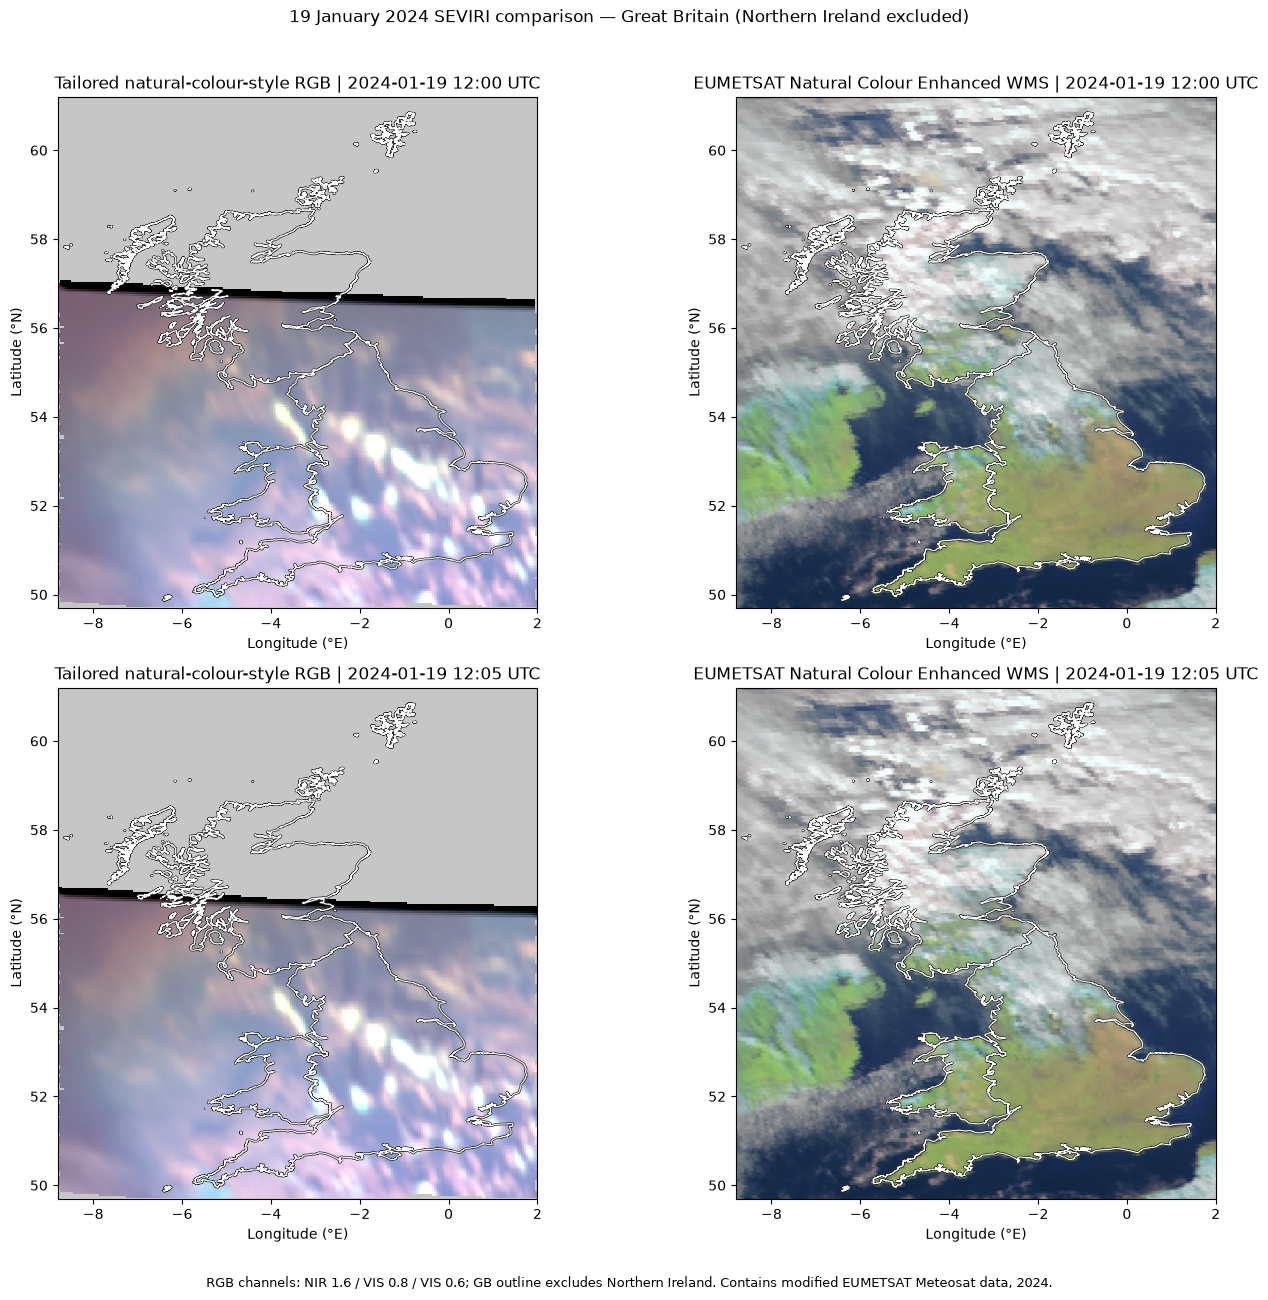

In [56]:
# Compare calibrated natural-colour-style RGB with the same-time EUMETSAT WMS preview.
import datetime as dt
import io
import json
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import requests
import xarray as xr
from PIL import Image as PILImage

GB_BOUNDARY_FILE = Path(
    "/Users/mans5211/GitHub-repos/Met-Office-Solar-Luke/data/inputs/boundaries/gadm41_GBR_1.json"
)
if not GB_BOUNDARY_FILE.exists():
    raise FileNotFoundError(f"Update GB_BOUNDARY_FILE to the local GADM v4.1 file: {GB_BOUNDARY_FILE}")

# Build one line set from the UK file, deliberately omitting Northern Ireland.
with GB_BOUNDARY_FILE.open() as f:
    boundary_geojson = json.load(f)
gb_line_segments = []
for feature in boundary_geojson["features"]:
    if feature["properties"].get("NAME_1") == "NorthernIreland":
        continue
    geometry = feature["geometry"]
    polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
    for polygon in polygons:
        for ring in polygon:
            gb_line_segments.append(np.asarray(ring, dtype=float)[:, :2])

# Select the newest tailored file for each sensing interval in the January 19 folder.
archive_candidates = list(JAN19_OUTPUT_DIRECTORY.glob("HRSEVIRI_*.zip"))
newest_by_scan = {}
for candidate in archive_candidates:
    scan_key = candidate.name.split("_epct_")[0]
    if scan_key not in newest_by_scan or candidate.stat().st_mtime > newest_by_scan[scan_key].stat().st_mtime:
        newest_by_scan[scan_key] = candidate
jan19_archives = [newest_by_scan[k] for k in sorted(newest_by_scan)]
if len(jan19_archives) < 2:
    raise FileNotFoundError(
        f"Need two tailored January 19 files in {JAN19_OUTPUT_DIRECTORY}; found {len(jan19_archives)}. Run the tailoring cell first."
    )

# EUMETSAT's warm-channel reflectances use pi * radiance * d^2 / (solar irradiance * cos(solar zenith)).
def solar_geometry(latitudes, longitudes, timestamp):
    day_fraction = (timestamp.timetuple().tm_yday - 1 + (timestamp.hour - 12 + timestamp.minute / 60) / 24)
    gamma = 2 * np.pi * day_fraction / 365.0
    equation_of_time = 229.18 * (0.000075 + 0.001868*np.cos(gamma) - 0.032077*np.sin(gamma)
                                 - 0.014615*np.cos(2*gamma) - 0.040849*np.sin(2*gamma))
    declination = (0.006918 - 0.399912*np.cos(gamma) + 0.070257*np.sin(gamma)
                   - 0.006758*np.cos(2*gamma) + 0.000907*np.sin(2*gamma)
                   - 0.002697*np.cos(3*gamma) + 0.00148*np.sin(3*gamma))
    utc_minutes = timestamp.hour * 60 + timestamp.minute + timestamp.second / 60
    solar_minutes = utc_minutes + equation_of_time + 4 * longitudes
    hour_angle = np.deg2rad(solar_minutes / 4 - 180)
    lat_radians = np.deg2rad(latitudes)
    cos_zenith = np.sin(lat_radians) * np.sin(declination) + np.cos(lat_radians) * np.cos(declination) * np.cos(hour_angle)
    earth_sun_distance_au = 1.00014 - 0.01671*np.cos(gamma) - 0.00014*np.cos(2*gamma)
    return cos_zenith, earth_sun_distance_au

# MSG-4 band solar irradiances for VIS0.6, VIS0.8, NIR1.6, respectively.
solar_irradiance = {"channel_1": 65.2656, "channel_2": 73.1692, "channel_3": 61.9416}
rgb_snapshots = []
for archive_path in jan19_archives[:2]:
    with zipfile.ZipFile(archive_path) as archive:
        nc_members = [x for x in archive.namelist() if x.lower().endswith((".nc", ".nc4"))]
        if len(nc_members) != 1:
            raise ValueError(f"Expected one NetCDF file in {archive_path.name}, found {nc_members}")
        with xr.open_dataset(io.BytesIO(archive.read(nc_members[0])), engine="h5netcdf") as ds:
            start = dt.datetime.strptime(ds.attrs["EPCT_start_sensing_time"], "%Y%m%dT%H%M%SZ")
            stop = dt.datetime.strptime(ds.attrs["EPCT_stop_sensing_time"], "%Y%m%dT%H%M%SZ")
            timestamp = start + (stop - start) / 2
            lat2d, lon2d = np.meshgrid(ds["lat"].values, ds["lon"].values, indexing="ij")
            cos_zenith, distance_au = solar_geometry(lat2d, lon2d, timestamp)
            channel_reflectance = {}
            for channel, calibration_attr in (("channel_3", "ch03_cal"), ("channel_2", "ch02_cal"), ("channel_1", "ch01_cal")):
                radiance = ds[channel].values.copy()
                fill_value = float(ds.attrs[calibration_attr].split()[0])
                invalid = ~np.isfinite(radiance) | np.isclose(radiance, fill_value, atol=1e-6) | (cos_zenith <= 0)
                reflectance = np.full(radiance.shape, np.nan, dtype=np.float32)
                np.divide(np.pi * radiance * distance_au**2,
                          solar_irradiance[channel] * cos_zenith,
                          out=reflectance, where=~invalid)
                channel_reflectance[channel] = reflectance
            rgb_snapshots.append({
                "label": start.strftime("%Y-%m-%d %H:%M UTC"),
                "lat": ds["lat"].values,
                "lon": ds["lon"].values,
                "bands": [channel_reflectance["channel_3"], channel_reflectance["channel_2"], channel_reflectance["channel_1"]],
            })

# Robust per-band display stretch shared across both scans.
rgb_limits = []
for band_index in range(3):
    valid_values = np.concatenate([s["bands"][band_index][np.isfinite(s["bands"][band_index])].ravel() for s in rgb_snapshots])
    rgb_limits.append(np.nanpercentile(valid_values, [2, 98]))

# Ask WMS for the matching nominal five-minute timestamps. WMS 1.3.0 EPSG:4326 bbox order is S,W,N,E.
wms_base_url = "https://view.eumetsat.int/geoserver/ows"
wms_layer = "msg_rss:rgb_naturalenhncd_nrt"
preview_times = ["2024-01-19T12:00:00.000Z", "2024-01-19T12:05:00.000Z"]
wms_previews = []
for preview_time in preview_times:
    response = requests.get(wms_base_url, params={
        "service": "WMS", "request": "GetMap", "version": "1.3.0",
        "layers": wms_layer, "styles": "", "format": "image/png",
        "crs": "EPSG:4326", "bbox": "49.7,-8.8,61.2,2.0",
        "width": 760, "height": 900, "time": preview_time,
    }, timeout=90)
    content_type = response.headers.get("Content-Type", "")
    if response.ok and content_type.startswith("image/"):
        wms_previews.append((np.asarray(PILImage.open(io.BytesIO(response.content)).convert("RGB")), None))
    else:
        body = response.text[:350].replace("\n", " ")
        wms_previews.append((None, f"WMS unavailable ({response.status_code}): {body}"))

fig, axes = plt.subplots(2, 2, figsize=(14, 13))
for row, (snapshot, (preview_array, preview_error)) in enumerate(zip(rgb_snapshots, wms_previews)):
    bands = snapshot["bands"]
    valid = np.logical_and.reduce([np.isfinite(b) for b in bands])
    rgb = np.zeros((*bands[0].shape, 3), dtype=np.float32)
    for component, (band, (low, high)) in enumerate(zip(bands, rgb_limits)):
        scaled = np.clip((band - low) / max(high - low, 1e-8), 0, 1)
        rgb[..., component] = np.power(np.nan_to_num(scaled), 0.85)
    rgb[~valid] = (0.78, 0.78, 0.78)
    extent = (float(snapshot["lon"].min()), float(snapshot["lon"].max()), float(snapshot["lat"].min()), float(snapshot["lat"].max()))

    ax = axes[row, 0]
    ax.imshow(rgb, extent=extent, origin="lower", interpolation="nearest")
    ax.set_title(f"Tailored natural-colour-style RGB | {snapshot['label']}")
    ax.set_facecolor("#d0d0d0")
    ax = axes[row, 1]
    if preview_array is not None:
        ax.imshow(preview_array, extent=(-8.8, 2.0, 49.7, 61.2), origin="upper")
        ax.set_title(f"EUMETSAT Natural Colour Enhanced WMS | {snapshot['label']}")
    else:
        ax.set_facecolor("#eeeeee")
        ax.text(0.5, 0.5, preview_error, ha="center", va="center", wrap=True, transform=ax.transAxes)
        ax.set_title(f"EUMETSAT WMS | {snapshot['label']}")
    for axis in (axes[row, 0], axes[row, 1]):
        axis.add_collection(LineCollection(gb_line_segments, colors="#222222", linewidths=1.8, zorder=4))
        axis.add_collection(LineCollection(gb_line_segments, colors="#ffffff", linewidths=0.8, zorder=5))
        axis.set_xlim(-8.8, 2.0)
        axis.set_ylim(49.7, 61.2)
        axis.set_xlabel("Longitude (°E)")
        axis.set_ylabel("Latitude (°N)")

fig.suptitle("19 January 2024 SEVIRI comparison — Great Britain (Northern Ireland excluded)", y=0.995)
fig.text(0.5, 0.012, "RGB channels: NIR 1.6 / VIS 0.8 / VIS 0.6; GB outline excludes Northern Ireland. Contains modified EUMETSAT Meteosat data, 2024.", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.035, 1, 0.98))
# fig

## 9. Inspect the original 19 January 12:00 native RSS scan

This downloads the original 12:00 UTC RSS product as supplied by EUMETSAT and extracts its native `.nat` file. It bypasses Data Tailor completely: no GB crop, channel selection, or reprojection is applied. The source is a Rapid Scan segment, not a full-disk image. The next cell uses Satpy's SEVIRI reader and its built-in `natural_color` composite, then compares the whole native scan with the same-time Natural Colour Enhanced WMS preview cropped to the study area. No political outlines are added.

Satpy is an additional dependency for reading the binary native file. If the import check in the visualization cell fails, run `%pip install satpy` in a notebook cell, restart the kernel, then rerun the setup/search, download, and visualization cells.

In [51]:
# Download and safely extract the original Jan 19 12:00 source product.
import shutil
import time
import zipfile
from pathlib import Path

if "jan19_products" not in globals() or not jan19_products:
    raise RuntimeError("Run the January 19 product search cell first.")

# EUMDAC prints this product timestamp as 20240119120416.146...Z
# (without the T and without rounding away fractional seconds).
JAN19_NOON_SCAN_END_ID = "20240119120416"
jan19_native_product = next(
    (
        product for product in jan19_products
        if JAN19_NOON_SCAN_END_ID in "".join(ch for ch in str(product) if ch.isdigit())
    ),
    None,
)
if jan19_native_product is None:
    available_ids = [str(product) for product in jan19_products]
    raise LookupError(
        "Could not identify the 12:00 UTC scan (expected product timestamp "
        f"{JAN19_NOON_SCAN_END_ID}). Products returned: {available_ids}"
    )
print(f"Selected the 12:00 UTC scan product: {jan19_native_product}")

JAN19_NATIVE_DIRECTORY = JAN19_OUTPUT_DIRECTORY / "original_native_product"
JAN19_NATIVE_DIRECTORY.mkdir(parents=True, exist_ok=True)
jan19_native_archive = JAN19_NATIVE_DIRECTORY / f"{jan19_native_product}.zip"
jan19_native_started = time.perf_counter()

if not jan19_native_archive.exists() or jan19_native_archive.stat().st_size == 0:
    partial_archive = jan19_native_archive.with_suffix(".zip.part")
    print(f"Downloading original 12:00 UTC RSS product: {jan19_native_product}")
    try:
        with jan19_native_product.open() as source, partial_archive.open("wb") as target:
            shutil.copyfileobj(source, target)
        partial_archive.replace(jan19_native_archive)
    except Exception:
        partial_archive.unlink(missing_ok=True)
        raise
else:
    print(f"Using existing original archive: {jan19_native_archive}")

with zipfile.ZipFile(jan19_native_archive) as archive:
    bad_member = archive.testzip()
    if bad_member is not None:
        raise RuntimeError(f"ZIP integrity check failed at: {bad_member}")
    native_members = [name for name in archive.namelist() if name.lower().endswith(".nat")]
    if len(native_members) != 1:
        raise ValueError(f"Expected one native .nat file, found: {native_members}")
    # Use only the member basename to avoid writing outside the destination folder.
    jan19_native_file = JAN19_NATIVE_DIRECTORY / Path(native_members[0]).name
    if not jan19_native_file.exists() or jan19_native_file.stat().st_size == 0:
        with archive.open(native_members[0]) as source, jan19_native_file.open("wb") as target:
            shutil.copyfileobj(source, target)

print(f"Original archive: {jan19_native_archive} ({jan19_native_archive.stat().st_size:,} bytes)")
print(f"Native file: {jan19_native_file} ({jan19_native_file.stat().st_size:,} bytes)")
print(f"Download, validation, and extraction elapsed: {time.perf_counter() - jan19_native_started:.1f} seconds")

Selected the 12:00 UTC scan product: MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA
Original archive: data/satellite/rss_2024_test/jan19_2024_test/original_native_product/MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA.zip (60,433,647 bytes)
Native file: data/satellite/rss_2024_test/jan19_2024_test/original_native_product/MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA.nat (102,210,123 bytes)
Download, validation, and extraction elapsed: 6.3 seconds


### Render the native scan and compare with the WMS preview

Satpy reads and calibrates the original binary scan. Its built-in `natural_color` composite uses the three daylight channels and the instrument-specific solar-angle correction. The native pane retains the product's full RSS scan extent; the WMS pane is the geographic crop around Great Britain.

/var/folders/hr/8b35c81n5gs9czlq47x9dtk00000gp/T/ipykernel_97065/652912598.py:4: UserWarning: 'satpy.writers.get_enhanced_image' has been moved to 'satpy.enhancements.enhancer.get_enhanced_image'. Import from the new location instead (ex. 'from satpy.enhancements.enhancer import get_enhanced_image'). The old import paths will be removed in Satpy 1.0
  from satpy.writers import get_enhanced_image
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..2.5270226].


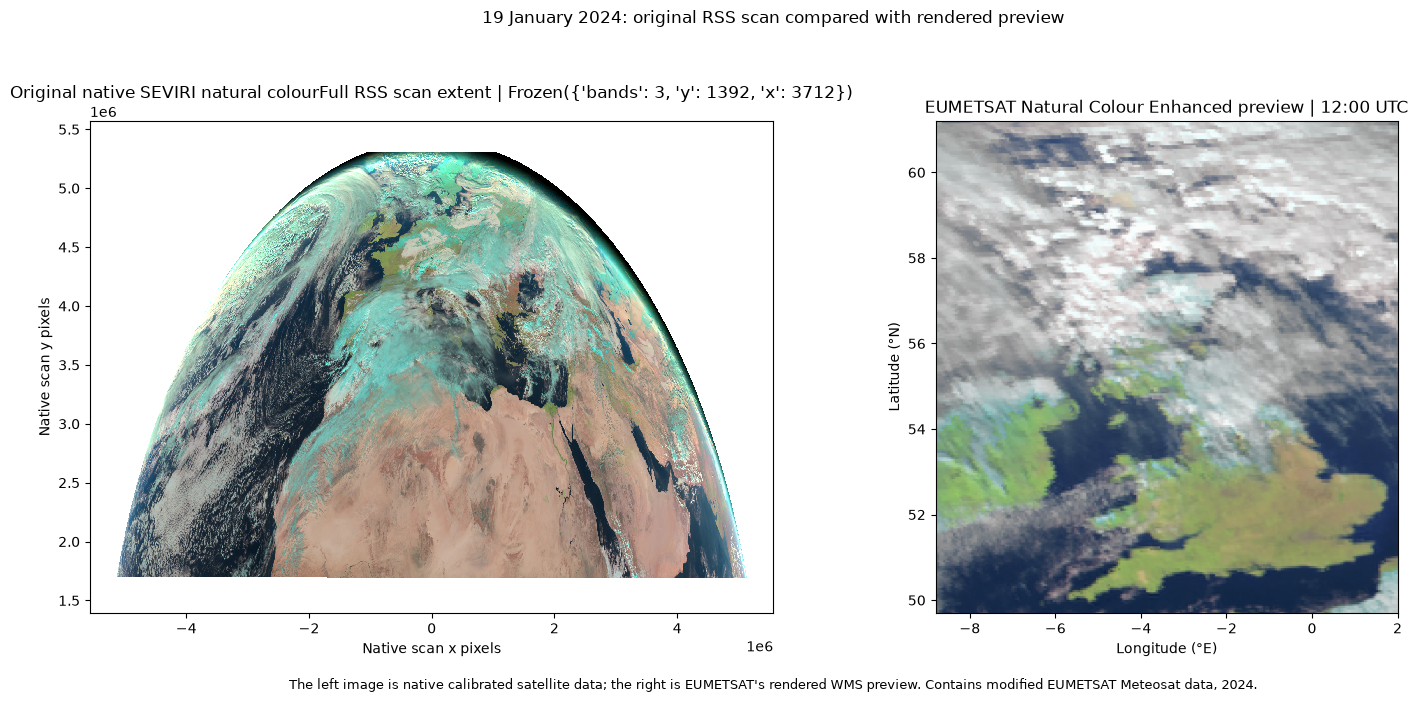

In [55]:
# Read the complete native RSS scan (no Data Tailor, crop, or reprojection).
try:
    from satpy import Scene
    from satpy.enhancements.enhancer import get_enhanced_image
except ImportError as exc:
    raise ImportError(
        "Satpy is required to read this native SEVIRI file. Install `satpy` "
        "in this notebook kernel, restart the kernel, then rerun this cell."
    ) from exc

import io
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image as PILImage

native_scene = Scene(
    filenames=[str(jan19_native_file)],
    reader="seviri_l1b_native",
)
native_scene.load(["natural_color"], upper_right_corner="NE")
native_composite = get_enhanced_image(native_scene["natural_color"]).data.clip(0, 1)

# Request the WMS enhanced natural-colour preview for the same nominal scan time.
preview_response = requests.get(
    "https://view.eumetsat.int/geoserver/ows",
    params={
        "service": "WMS", "request": "GetMap", "version": "1.3.0",
        "layers": "msg_rss:rgb_naturalenhncd_nrt", "styles": "",
        "format": "image/png", "crs": "EPSG:4326",
        # WMS 1.3.0 EPSG:4326 axis order is south, west, north, east.
        "bbox": "49.7,-8.8,61.2,2.0", "width": 760, "height": 900,
        "time": "2024-01-19T12:00:00.000Z",
    },
    timeout=90,
)
preview_response.raise_for_status()
if not preview_response.headers.get("Content-Type", "").startswith("image/"):
    raise RuntimeError(f"WMS did not return an image: {preview_response.text[:350]}")
preview_rgb = np.asarray(PILImage.open(io.BytesIO(preview_response.content)).convert("RGB"))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
native_composite.plot.imshow(ax=axes[0], rgb="bands")
axes[0].set_title(
    "Original native SEVIRI natural colour\n"
    f"Full RSS scan extent | {dict(native_scene['natural_color'].sizes)}"
)
axes[0].set_xlabel("Native scan x pixels")
axes[0].set_ylabel("Native scan y pixels")
axes[1].imshow(preview_rgb, extent=(-8.8, 2.0, 49.7, 61.2), origin="upper")
axes[1].set_title("EUMETSAT Natural Colour Enhanced preview | 12:00 UTC")
axes[1].set_xlim(-8.8, 2.0)
axes[1].set_ylim(49.7, 61.2)
axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°N)")
fig.suptitle("19 January 2024: original RSS scan compared with rendered preview")
fig.text(
    0.5, 0.01,
    "The left image is native calibrated satellite data; the right is EUMETSAT's rendered WMS preview. "
    "Contains modified EUMETSAT Meteosat data, 2024.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=(0, 0.035, 1, 0.94))
# fig

## 10. Diagnose the tailored northern cutoff

This compares the original native VIS006 source footprint with the 12:00 Data Tailor output on the exact same geographic grid. The native channel is nearest-neighbor resampled only for this diagnostic; this avoids comparing different projections or confusing a map extent with actual valid pixels. A native-valid/tailored-invalid region points to Data Tailor processing or its output encoding. If both masks agree, the earlier RGB/calibration/plotting logic is the more likely cause.


/Users/mans5211/GitHub-repos/PVNet/.venv/lib/python3.12/site-packages/pyproj/crs/crs.py:1295: UserWarning: You will likely lose important projection information when converting to a PROJ string from another format. See: https://proj.org/faq.html#what-is-the-best-format-for-describing-coordinate-reference-systems
  proj = self._crs.to_proj4(version=version)


Tailored archive: HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_ee91858c_FPRC.zip
NetCDF dimensions (channel_1): {'lat': 288, 'lon': 270}; valid GeoTransform: not present
Native VIS006 grid: (1392, 3712); Satpy area extent: (np.float32(-5.5702485e+06), np.float32(1.3936872e+06), np.float32(5.567248e+06), np.float32(5.5702485e+06))
Tailored-grid valid pixels: native=100.0%, tailored=61.7%
Valid-pixel fraction by latitude band:
  49.7–54.0°N: native=100.0%, tailored=99.3%
  54.0–57.0°N: native=100.0%, tailored=93.8%
  57.0–59.0°N: native=100.0%, tailored=0.3%
  59.0–61.2°N: native=100.0%, tailored=0.0%


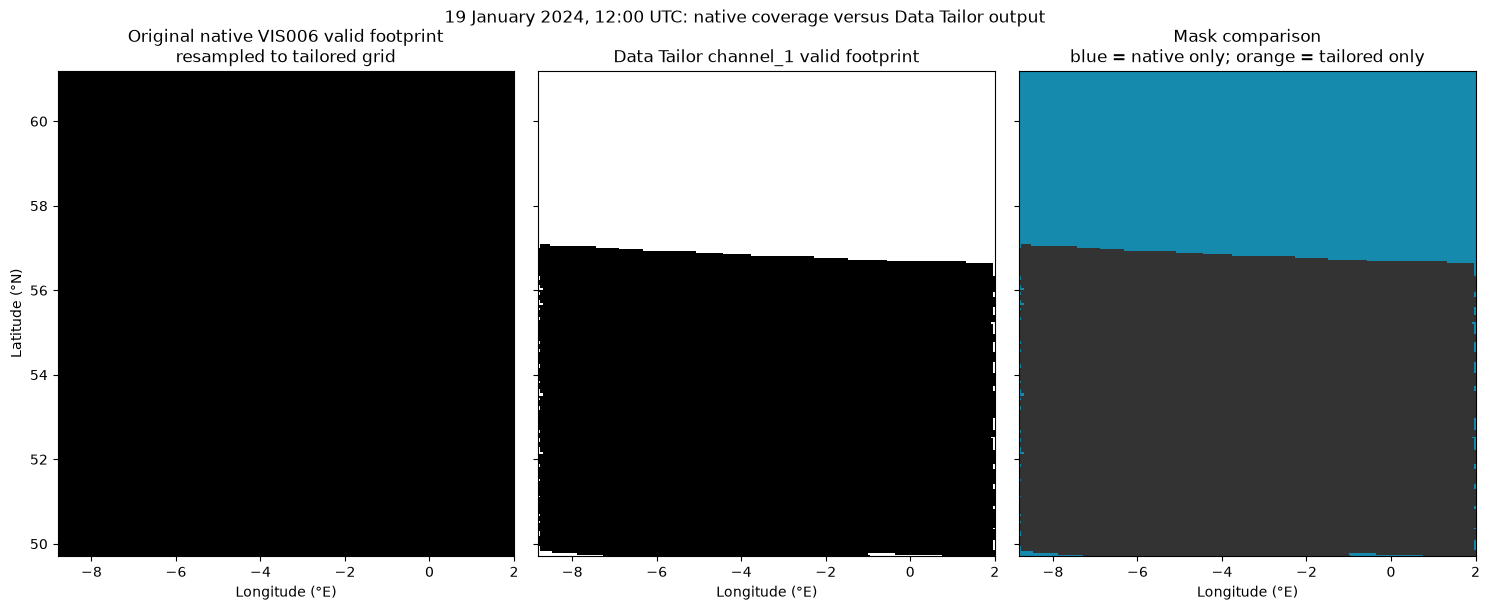

In [60]:
# Compare valid-pixel masks for original native VIS006 and tailored VIS 0.6 μm.
import io
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from pyresample.geometry import AreaDefinition
from pyresample.kd_tree import resample_nearest

# Use only the 12:00 UTC tailored file; do not accidentally select the 12:05 scan.
noon_tailored_candidates = sorted(JAN19_OUTPUT_DIRECTORY.glob(
    "HRSEVIRI_20240119T120008Z_*_FPRC.zip"
))
if len(noon_tailored_candidates) != 1:
    raise FileNotFoundError(
        f"Expected one tailored 12:00 archive, found: {noon_tailored_candidates}"
    )
noon_tailored_archive = noon_tailored_candidates[0]
with zipfile.ZipFile(noon_tailored_archive) as archive:
    nc_member = next(
        name for name in archive.namelist()
        if name.lower().endswith((".nc", ".nc4"))
    )
    with xr.open_dataset(io.BytesIO(archive.read(nc_member)), engine="h5netcdf") as ds:
        tail_vis = ds["channel_1"].values.copy()
        lat = ds["lat"].values.astype(float)
        lon = ds["lon"].values.astype(float)
        fill_value = float(ds.attrs["ch01_cal"].split()[0])
        tail_valid = np.isfinite(tail_vis) & ~np.isclose(tail_vis, fill_value, atol=1e-6)
        geotransform = ds.attrs.get("GeoTransform", "not present")
        tail_dims = dict(ds["channel_1"].sizes)

# Ensure the original native file is loaded as the source of geographic coverage.
if "native_scene" not in globals():
    from satpy import Scene
    native_scene = Scene(
        filenames=[str(jan19_native_file)], reader="seviri_l1b_native"
    )
    native_scene.load(["VIS006"], upper_right_corner="NE")
elif "VIS006" not in native_scene:
    native_scene.load(["VIS006"], upper_right_corner="NE")

native_vis = native_scene["VIS006"]
native_area = native_vis.attrs.get("area")
if native_area is None or not hasattr(native_area, "proj_dict"):
    raise TypeError(
        "Satpy did not attach a projected area to native VIS006; "
        "cannot safely compare its footprint to the tailored grid."
    )
source_values = np.asarray(native_vis.values, dtype=np.float32)
source_valid = np.isfinite(source_values)

# Construct pixel-edge bounds from the tailored grid's 1-D cell-center coordinates.
lon_step = float(np.nanmedian(np.diff(lon)))
lat_step = float(np.nanmedian(np.diff(lat)))
if not np.isfinite(lon_step) or not np.isfinite(lat_step):
    raise ValueError("Could not infer regular tailored-grid spacing from lat/lon coordinates.")
west, east = float(np.nanmin(lon) - abs(lon_step) / 2), float(np.nanmax(lon) + abs(lon_step) / 2)
south, north = float(np.nanmin(lat) - abs(lat_step) / 2), float(np.nanmax(lat) + abs(lat_step) / 2)
tail_area = AreaDefinition(
    "tailored_grid", "Data Tailor geographic grid", "tailored_grid",
    {"proj": "longlat", "datum": "WGS84", "ellps": "WGS84"},
    len(lon), len(lat), (west, south, east, north),
)

# A 7 km radius accommodates the native ~3 km pixels and nearest-neighbor mapping.
native_on_tail_grid = resample_nearest(
    native_area, source_values, tail_area,
    radius_of_influence=7000, fill_value=np.nan,
).astype(np.float32)
# Pyresample returns rows north-to-south and columns west-to-east; align to the
# coordinate ordering in the NetCDF in case it is ascending/descending.
if lat[0] < lat[-1]:
    native_on_tail_grid = native_on_tail_grid[::-1, :]
if lon[0] > lon[-1]:
    native_on_tail_grid = native_on_tail_grid[:, ::-1]
native_valid = np.isfinite(native_on_tail_grid)
if native_valid.shape != tail_valid.shape:
    raise ValueError(
        f"Grid shape mismatch: native={native_valid.shape}, tailored={tail_valid.shape}"
    )

print(f"Tailored archive: {noon_tailored_archive.name}")
print(f"NetCDF dimensions (channel_1): {tail_dims}; valid GeoTransform: {geotransform}")
print(f"Native VIS006 grid: {source_values.shape}; Satpy area extent: {native_area.area_extent}")
print(f"Tailored-grid valid pixels: native={native_valid.mean():.1%}, tailored={tail_valid.mean():.1%}")
print("Valid-pixel fraction by latitude band:")
for lower, upper in [(49.7, 54.0), (54.0, 57.0), (57.0, 59.0), (59.0, 61.2)]:
    rows = (lat >= lower) & (lat < upper)
    if np.any(rows):
        print(
            f"  {lower:.1f}–{upper:.1f}°N: "
            f"native={native_valid[rows].mean():.1%}, "
            f"tailored={tail_valid[rows].mean():.1%}"
        )

# Four states distinguish missing coverage from values present in only one product.
# 0 = neither valid; 1 = both valid; 2 = native only; 3 = tailored only.
state = np.zeros(tail_valid.shape, dtype=np.uint8)
state[native_valid & tail_valid] = 1
state[native_valid & ~tail_valid] = 2
state[~native_valid & tail_valid] = 3
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharex=True, sharey=True)
extent = (west, east, south, north)
axes[0].imshow(native_valid, extent=extent, origin="lower", interpolation="nearest", cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title("Original native VIS006 valid footprint\nresampled to tailored grid")
axes[1].imshow(tail_valid, extent=extent, origin="lower", interpolation="nearest", cmap="gray_r", vmin=0, vmax=1)
axes[1].set_title("Data Tailor channel_1 valid footprint")
axes[2].imshow(
    state, extent=extent, origin="lower", interpolation="nearest",
    cmap=ListedColormap(["#eeeeee", "#333333", "#168aad", "#f4a261"]),
    vmin=0, vmax=3,
)
axes[2].set_title("Mask comparison\nblue = native only; orange = tailored only")
for ax in axes:
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")
fig.suptitle("19 January 2024, 12:00 UTC: native coverage versus Data Tailor output")
fig.tight_layout()
# fig # this seems to be just repeating the figure(s) twice


## 11. Controlled Data Tailor run with nearest-neighbor resampling

This submits only the 12:00 UTC source product, keeping the same channel selection, geographic ROI, output format, and requested target resolution as the bilinear run. The result is stored in a separate `nearest_diagnostic` folder. If the result already exists, rerunning the cell reuses it unless `FORCE_NEAREST_REPROCESS` is set to `True`.


In [62]:
# Submit a single nearest-neighbor control job; preserve existing bilinear outputs.
import fnmatch
import shutil
import time
from pathlib import Path

if "jan19_token" not in globals() or "jan19_products" not in globals():
    raise RuntimeError("Run the January 19 search cell first so the token and products are available.")

JAN19_NEAREST_DIRECTORY = JAN19_OUTPUT_DIRECTORY / "nearest_diagnostic"
JAN19_NEAREST_DIRECTORY.mkdir(parents=True, exist_ok=True)
nearest_existing = list(JAN19_NEAREST_DIRECTORY.glob("HRSEVIRI_*.zip"))
FORCE_NEAREST_REPROCESS = False

if nearest_existing and not FORCE_NEAREST_REPROCESS:
    print("Reusing existing nearest-neighbor diagnostic output:")
    for path in nearest_existing:
        print(f"- {path}")
else:
    # Re-select the exact product by its 12:04:16.146 UTC sensing-end time.
    JAN19_NOON_SCAN_END_ID = "20240119120416"
    nearest_source_product = next(
        (product for product in jan19_products
         if JAN19_NOON_SCAN_END_ID in "".join(ch for ch in str(product) if ch.isdigit())),
        None,
    )
    if nearest_source_product is None:
        raise LookupError(
            "Could not identify the 12:00 UTC source product in jan19_products: "
            f"{[str(product) for product in jan19_products]}"
        )

    nearest_tailor = eumdac.DataTailor(jan19_token)
    nearest_chain = eumdac.tailor_models.Chain(
        product="HRSEVIRI",
        format="netcdf4",
        filter={"bands": SELECTED_DATA_CHANNELS},
        projection="geographic",
        resample_method="near",  # Data Tailor ID for nearest-neighbor resampling.
        resample_resolution=[0.05, 0.03],  # Keep X/Y target resolution identical to the bilinear run.
        roi=JAN19_ROI_NSWE,
        compression={"format": "zip"},
    )

    print(f"Submitting nearest-neighbor diagnostic for {nearest_source_product}...")
    nearest_started = time.perf_counter()
    nearest_customisation = nearest_tailor.new_customisation(
        nearest_source_product, chain=nearest_chain
    )
    while True:
        nearest_status = nearest_customisation.status
        print(f"  status: {nearest_status}")
        if nearest_status == "DONE":
            break
        if nearest_status in {"ERROR", "FAILED", "KILLED", "DELETED", "INACTIVE"}:
            raise RuntimeError(
                "Nearest-neighbor Data Tailor job failed "
                f"(status={nearest_status}); inspect the job in the EUMETSAT portal."
            )
        time.sleep(10)

    nearest_outputs = fnmatch.filter(nearest_customisation.outputs, "*")
    if not nearest_outputs:
        raise RuntimeError("Nearest-neighbor Data Tailor job completed without output files.")
    for output_file in nearest_outputs:
        destination = JAN19_NEAREST_DIRECTORY / Path(output_file).name
        with nearest_customisation.stream_output(output_file) as source, destination.open("wb") as target:
            shutil.copyfileobj(source, target)
        print(f"Saved: {destination}")
    nearest_customisation.delete()
    print(f"Nearest-neighbor job elapsed: {time.perf_counter() - nearest_started:.1f} seconds")


Submitting nearest-neighbor diagnostic for MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA...
  status: RUNNING
  status: DONE
Saved: data/satellite/rss_2024_test/jan19_2024_test/nearest_diagnostic/HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_09159d46_FPRC.zip
Nearest-neighbor job elapsed: 91.4 seconds


### Compare nearest output with the bilinear result

Run this after the job above completes. It checks whether nearest-neighbor resampling restores the native source coverage in the north, and plots the bilinear/nearest mask difference on the same grid.


Nearest output: HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_09159d46_FPRC.zip
49.7–54.0°N: bilinear=99.3%, nearest=99.3%
54.0–57.0°N: bilinear=93.8%, nearest=91.1%
57.0–59.0°N: bilinear=0.3%, nearest=0.0%
59.0–61.2°N: bilinear=0.0%, nearest=0.0%


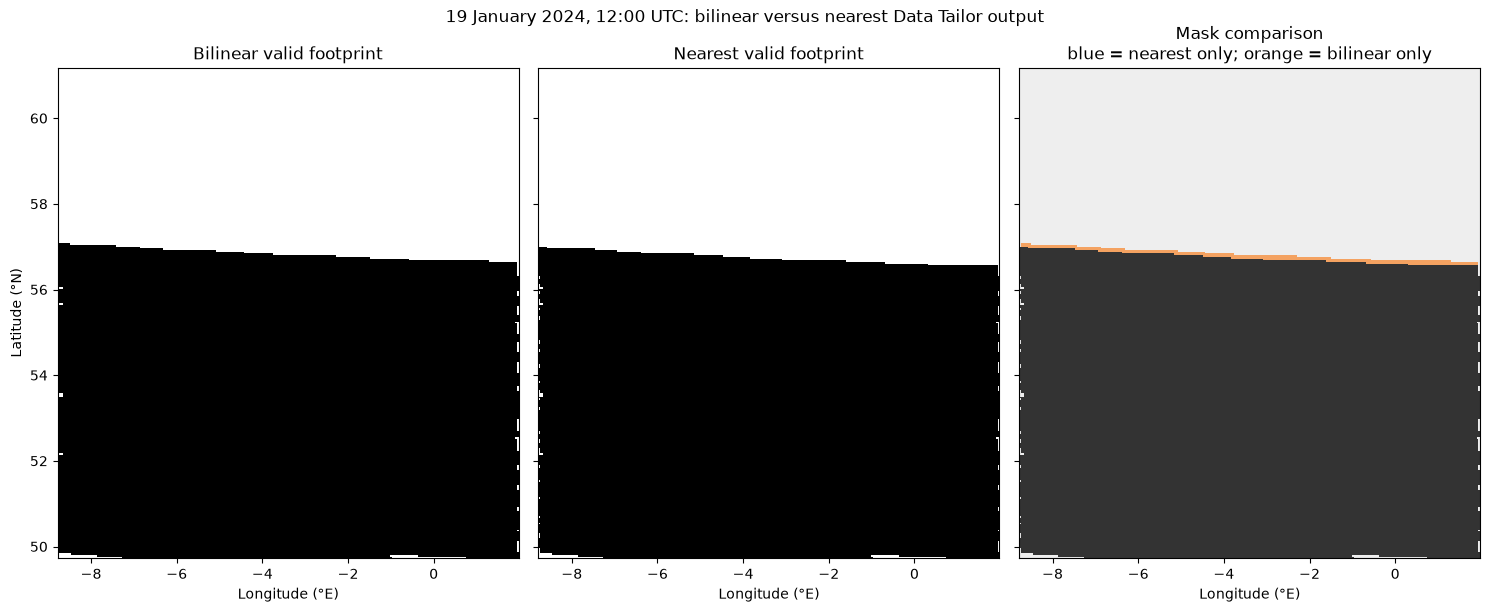

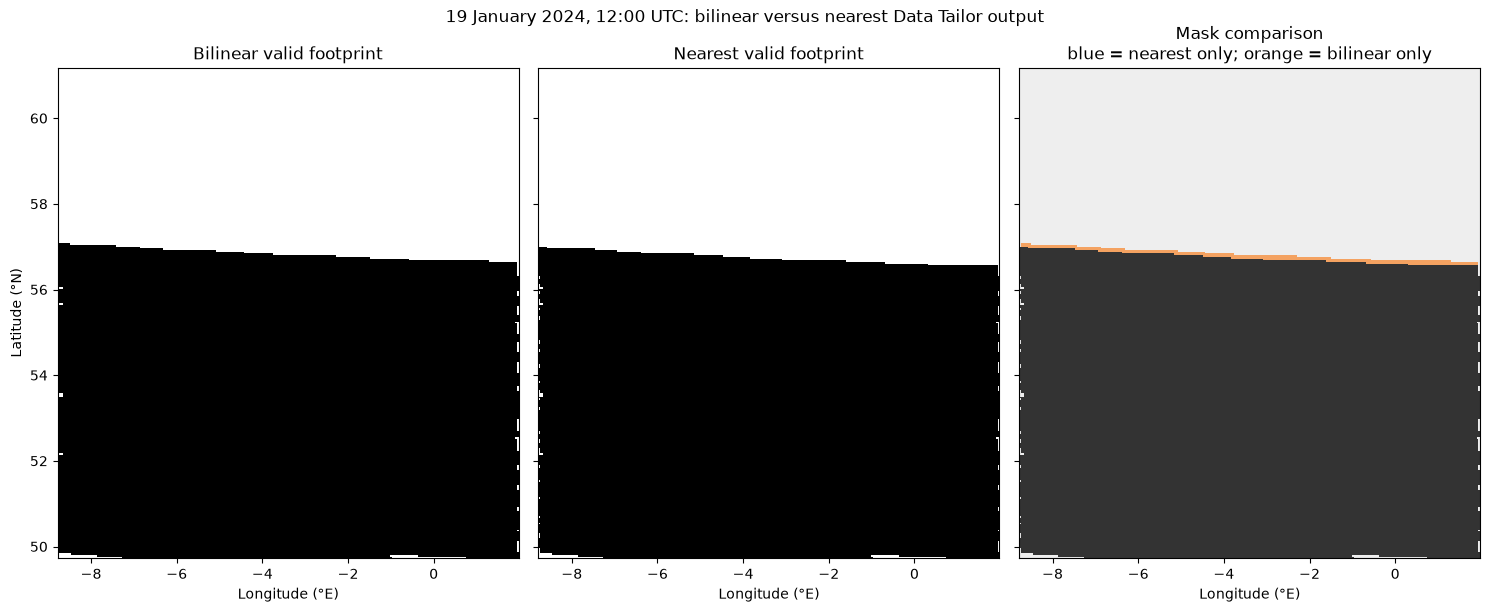

In [63]:
# Quantify whether nearest-neighbor resampling restores the missing northern rows.
import io
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.colors import ListedColormap

if "tail_valid" not in globals() or "lat" not in globals() or "lon" not in globals():
    raise RuntimeError("Run the Section 10 footprint diagnostic first.")
nearest_archives = sorted(JAN19_NEAREST_DIRECTORY.glob("HRSEVIRI_*.zip"))
if len(nearest_archives) != 1:
    raise FileNotFoundError(
        f"Expected one nearest-neighbor ZIP in {JAN19_NEAREST_DIRECTORY}, found {nearest_archives}"
    )
with zipfile.ZipFile(nearest_archives[0]) as archive:
    nc_member = next(
        name for name in archive.namelist()
        if name.lower().endswith((".nc", ".nc4"))
    )
    with xr.open_dataset(io.BytesIO(archive.read(nc_member)), engine="h5netcdf") as ds:
        nearest_values = ds["channel_1"].values.copy()
        nearest_lat = ds["lat"].values.astype(float)
        nearest_lon = ds["lon"].values.astype(float)
        nearest_fill = float(ds.attrs["ch01_cal"].split()[0])
        nearest_valid = np.isfinite(nearest_values) & ~np.isclose(
            nearest_values, nearest_fill, atol=1e-6
        )

if nearest_valid.shape != tail_valid.shape or not np.allclose(nearest_lat, lat) or not np.allclose(nearest_lon, lon):
    raise ValueError(
        "Nearest and bilinear products do not share the same grid; compare the latitude/longitude coordinates before interpreting masks."
    )
print(f"Nearest output: {nearest_archives[0].name}")
for lower, upper in [(49.7, 54.0), (54.0, 57.0), (57.0, 59.0), (59.0, 61.2)]:
    rows = (lat >= lower) & (lat < upper)
    print(
        f"{lower:.1f}–{upper:.1f}°N: "
        f"bilinear={tail_valid[rows].mean():.1%}, "
        f"nearest={nearest_valid[rows].mean():.1%}"
    )

# 0 = both invalid, 1 = both valid, 2 = nearest only, 3 = bilinear only.
mask_state = np.zeros(tail_valid.shape, dtype=np.uint8)
mask_state[tail_valid & nearest_valid] = 1
mask_state[~tail_valid & nearest_valid] = 2
mask_state[tail_valid & ~nearest_valid] = 3
extent = (float(lon.min()), float(lon.max()), float(lat.min()), float(lat.max()))
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharex=True, sharey=True)
axes[0].imshow(tail_valid, extent=extent, origin="lower", interpolation="nearest", cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title("Bilinear valid footprint")
axes[1].imshow(nearest_valid, extent=extent, origin="lower", interpolation="nearest", cmap="gray_r", vmin=0, vmax=1)
axes[1].set_title("Nearest valid footprint")
axes[2].imshow(
    mask_state, extent=extent, origin="lower", interpolation="nearest",
    cmap=ListedColormap(["#eeeeee", "#333333", "#168aad", "#f4a261"]),
    vmin=0, vmax=3,
)
axes[2].set_title("Mask comparison\nblue = nearest only; orange = bilinear only")
for ax in axes:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")
fig.suptitle("19 January 2024, 12:00 UTC: bilinear versus nearest Data Tailor output")
fig.tight_layout()
fig


## 12. Isolate the geographic reprojection and ROI steps

The accepted `near` resampling method produced the same northern gap, so interpolation is not the main cause. This control asks Data Tailor only to convert the 12:00 product to NetCDF and retain channel 1. It deliberately omits the ROI, target projection, and resampling settings. Its output goes into a separate `native_grid_diagnostic` folder. Comparing its valid-data mask with Satpy's native channel will show whether the loss occurs during Data Tailor's basic read/NetCDF conversion or when the geographic ROI/reprojection chain is applied.


In [64]:
# Submit one minimal NetCDF conversion with no ROI or reprojection settings.
import fnmatch
import shutil
import time
from pathlib import Path

if "jan19_token" not in globals() or "jan19_products" not in globals():
    raise RuntimeError("Run the January 19 search cell first so the token and products are available.")

JAN19_NATIVE_GRID_DIRECTORY = JAN19_OUTPUT_DIRECTORY / "native_grid_diagnostic"
JAN19_NATIVE_GRID_DIRECTORY.mkdir(parents=True, exist_ok=True)
native_grid_existing = list(JAN19_NATIVE_GRID_DIRECTORY.glob("HRSEVIRI_*.zip"))
FORCE_NATIVE_GRID_REPROCESS = False

if native_grid_existing and not FORCE_NATIVE_GRID_REPROCESS:
    print("Reusing existing no-reprojection diagnostic output:")
    for path in native_grid_existing:
        print(f"- {path}")
else:
    JAN19_NOON_SCAN_END_ID = "20240119120416"
    native_grid_product = next(
        (product for product in jan19_products
         if JAN19_NOON_SCAN_END_ID in "".join(ch for ch in str(product) if ch.isdigit())),
        None,
    )
    if native_grid_product is None:
        raise LookupError("Could not identify the 12:00 UTC source product.")

    native_grid_tailor = eumdac.DataTailor(jan19_token)
    native_grid_chain = eumdac.tailor_models.Chain(
        product="HRSEVIRI",
        format="netcdf4",
        filter={"bands": ["channel_1"]},
        compression={"format": "zip"},
        # Intentionally omit projection, ROI, resample_method, and resolution.
    )
    print(f"Submitting no-reprojection conversion for {native_grid_product}...")
    native_grid_started = time.perf_counter()
    native_grid_job = native_grid_tailor.new_customisation(
        native_grid_product, chain=native_grid_chain
    )
    while True:
        native_grid_status = native_grid_job.status
        print(f"  status: {native_grid_status}")
        if native_grid_status == "DONE":
            break
        if native_grid_status in {"ERROR", "FAILED", "KILLED", "DELETED", "INACTIVE"}:
            raise RuntimeError(
                "No-reprojection Data Tailor job failed "
                f"(status={native_grid_status}); inspect the job in the EUMETSAT portal."
            )
        time.sleep(10)

    native_grid_outputs = fnmatch.filter(native_grid_job.outputs, "*")
    if not native_grid_outputs:
        raise RuntimeError("No-reprojection Data Tailor job completed without output files.")
    for output_file in native_grid_outputs:
        destination = JAN19_NATIVE_GRID_DIRECTORY / Path(output_file).name
        with native_grid_job.stream_output(output_file) as source, destination.open("wb") as target:
            shutil.copyfileobj(source, target)
        print(f"Saved: {destination}")
    native_grid_job.delete()
    print(f"No-reprojection job elapsed: {time.perf_counter() - native_grid_started:.1f} seconds")


Submitting no-reprojection conversion for MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA...
  status: RUNNING
  status: RUNNING
  status: DONE
Saved: data/satellite/rss_2024_test/jan19_2024_test/native_grid_diagnostic/HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_8d37368d_F.zip
No-reprojection job elapsed: 175.7 seconds


### Inspect the minimal NetCDF output

Run this after the previous cell completes. It reports the NetCDF coverage mask and compares the scan-row pattern with the original native VIS006 channel. The native product uses a different calibrated scale, so this comparison focuses on where data exist rather than matching radiance values.


Output file: HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_8d37368d_F.zip
Dimensions: {'y': 1392, 'x': 3712}
Coordinates: ['x', 'y']
Data variables: ['geostationary', 'channel_1']
Product processing metadata: {'EPCT_projection': 'null', 'EPCT_roi': 'null', 'EPCT_geospatial_lat_min': '-70.7011306', 'EPCT_geospatial_lat_max': '70.7054108'}
No-reprojection channel_1 dimensions: (1392, 3712)
No-reprojection channel_1 valid fraction: 59.8%
Calibration/fill value used for mask: -1.106128815562
Original native VIS006 dimensions: (1392, 3712)
Original native VIS006 positive finite fraction: 59.7%
Best row/column orientation match: vertical flip; IoU=99.8360%, pixel agreement=99.9019%


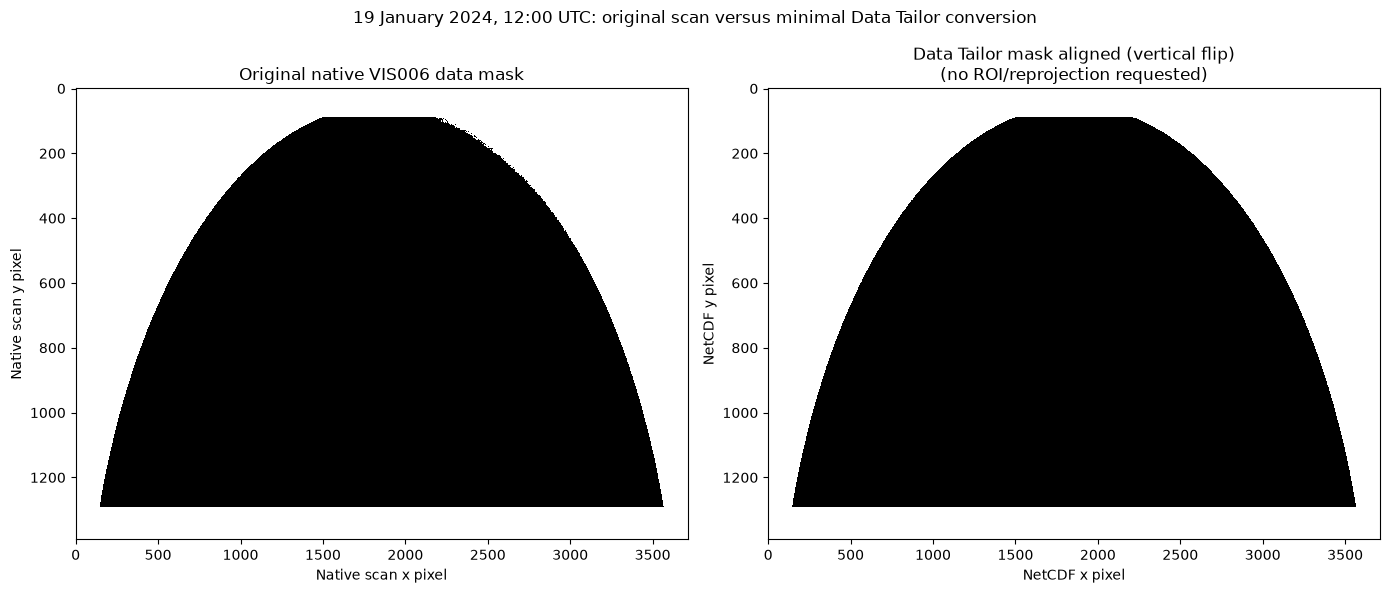

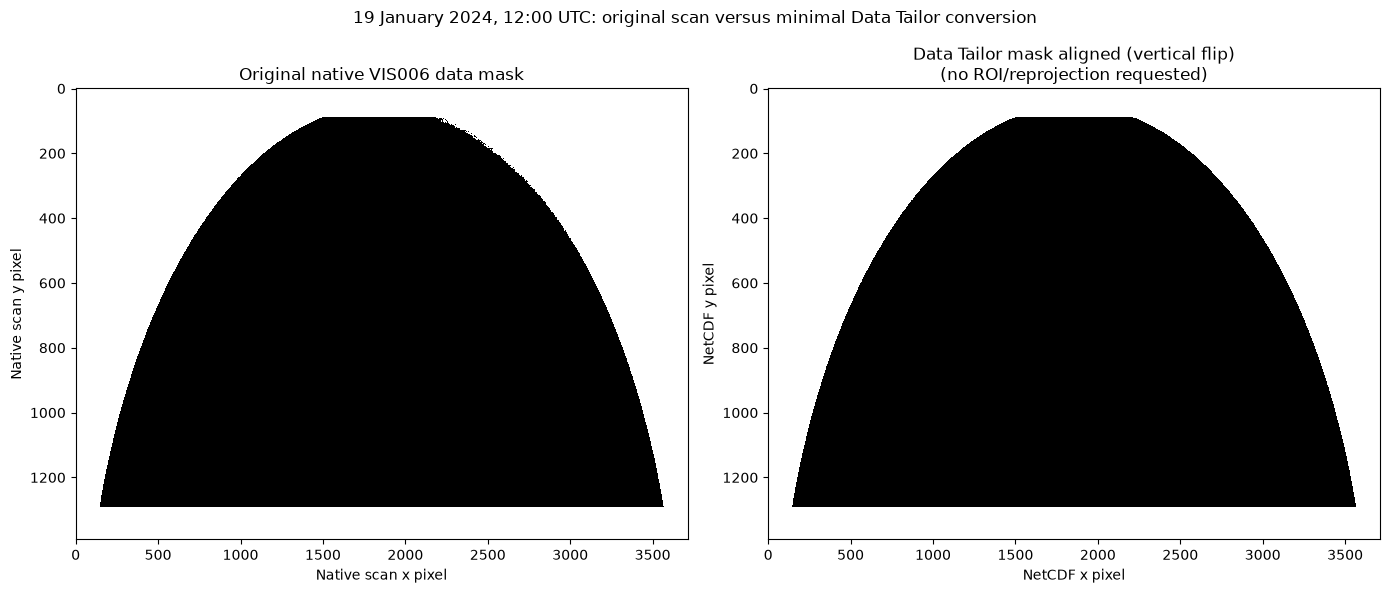

In [66]:
# Compare the no-reprojection NetCDF data mask with the original native scan.
import io
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

minimal_archives = sorted(JAN19_NATIVE_GRID_DIRECTORY.glob("HRSEVIRI_*.zip"))
if len(minimal_archives) != 1:
    raise FileNotFoundError(
        f"Expected one no-reprojection ZIP in {JAN19_NATIVE_GRID_DIRECTORY}, found {minimal_archives}"
    )
with zipfile.ZipFile(minimal_archives[0]) as archive:
    nc_members = [name for name in archive.namelist() if name.lower().endswith((".nc", ".nc4"))]
    if len(nc_members) != 1:
        raise ValueError(f"Expected one NetCDF member, found {nc_members}")
    with xr.open_dataset(io.BytesIO(archive.read(nc_members[0])), engine="h5netcdf") as ds:
        print(f"Output file: {minimal_archives[0].name}")
        print(f"Dimensions: {dict(ds.sizes)}")
        print(f"Coordinates: {list(ds.coords)}")
        print(f"Data variables: {list(ds.data_vars)}")
        print("Product processing metadata:", {
            key: ds.attrs.get(key) for key in
            ("EPCT_projection", "EPCT_roi", "EPCT_geospatial_lat_min", "EPCT_geospatial_lat_max")
        })
        if "channel_1" not in ds:
            raise KeyError("Expected channel_1 in the minimal NetCDF output.")
        tailored_native_values = ds["channel_1"].values.copy()
        fill_text = ds.attrs.get("ch01_cal")
        fill_value = float(fill_text.split()[0]) if fill_text else float(ds["channel_1"].attrs.get("_FillValue", np.nan))
        tailored_native_valid = np.isfinite(tailored_native_values)
        if np.isfinite(fill_value):
            tailored_native_valid &= ~np.isclose(tailored_native_values, fill_value, atol=1e-6)
        print(f"No-reprojection channel_1 dimensions: {tailored_native_values.shape}")
        print(f"No-reprojection channel_1 valid fraction: {tailored_native_valid.mean():.1%}")
        print(f"Calibration/fill value used for mask: {fill_value}")

if "native_scene" not in globals() or "VIS006" not in native_scene:
    from satpy import Scene
    native_scene = Scene(filenames=[str(jan19_native_file)], reader="seviri_l1b_native")
    native_scene.load(["VIS006"], upper_right_corner="NE")
native_values = np.asarray(native_scene["VIS006"].values, dtype=np.float32)
native_valid_mask = np.isfinite(native_values) & (native_values > 0)
print(f"Original native VIS006 dimensions: {native_values.shape}")
print(f"Original native VIS006 positive finite fraction: {native_valid_mask.mean():.1%}")

if native_valid_mask.shape != tailored_native_valid.shape:
    raise ValueError("Native and no-reprojection masks have different shapes.")
orientations = {
    "as stored": tailored_native_valid,
    "vertical flip": np.flipud(tailored_native_valid),
    "horizontal flip": np.fliplr(tailored_native_valid),
    "vertical + horizontal flip": np.flipud(np.fliplr(tailored_native_valid)),
}
def mask_agreement(mask):
    intersection = np.count_nonzero(native_valid_mask & mask)
    union = np.count_nonzero(native_valid_mask | mask)
    return intersection / max(union, 1), np.mean(native_valid_mask == mask)
orientation_scores = {name: mask_agreement(mask) for name, mask in orientations.items()}
best_orientation = max(orientation_scores, key=lambda name: orientation_scores[name][0])
tailored_native_aligned = orientations[best_orientation]
print(f"Best row/column orientation match: {best_orientation}; "
      f"IoU={orientation_scores[best_orientation][0]:.4%}, "
      f"pixel agreement={orientation_scores[best_orientation][1]:.4%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(native_valid_mask, origin="upper", interpolation="nearest", cmap="gray_r", vmin=0, vmax=1, aspect="auto")
axes[0].set_title("Original native VIS006 data mask")
axes[0].set_xlabel("Native scan x pixel")
axes[0].set_ylabel("Native scan y pixel")
axes[1].imshow(tailored_native_aligned, origin="upper", interpolation="nearest", cmap="gray_r", vmin=0, vmax=1, aspect="auto")
axes[1].set_title(f"Data Tailor mask aligned ({best_orientation})\n(no ROI/reprojection requested)")
axes[1].set_xlabel("NetCDF x pixel")
axes[1].set_ylabel("NetCDF y pixel")
fig.suptitle("19 January 2024, 12:00 UTC: original scan versus minimal Data Tailor conversion")
fig.tight_layout()
fig


## 13. Test geographic reprojection without an ROI

The no-reprojection NetCDF conversion preserves the source mask, so basic format conversion is working. This control applies the same geographic projection, `near` resampling, and target resolution as the tailored ROI product, but leaves ROI unset. It tells us whether the missing north is introduced by the projection/resampling itself or by the ROI clipping step. Only channel 1 and the 12:00 scan are used; the full projected RSS extent is saved separately.


In [67]:
# Submit a geographic projection control with no ROI.
import fnmatch
import shutil
import time
from pathlib import Path

if "jan19_token" not in globals() or "jan19_products" not in globals():
    raise RuntimeError("Run the January 19 search cell first so the token and products are available.")

JAN19_PROJECTION_NO_ROI_DIRECTORY = JAN19_OUTPUT_DIRECTORY / "projection_no_roi_diagnostic"
JAN19_PROJECTION_NO_ROI_DIRECTORY.mkdir(parents=True, exist_ok=True)
projection_no_roi_existing = list(JAN19_PROJECTION_NO_ROI_DIRECTORY.glob("HRSEVIRI_*.zip"))
FORCE_PROJECTION_NO_ROI_REPROCESS = False

if projection_no_roi_existing and not FORCE_PROJECTION_NO_ROI_REPROCESS:
    print("Reusing existing geographic-projection/no-ROI output:")
    for path in projection_no_roi_existing:
        print(f"- {path}")
else:
    JAN19_NOON_SCAN_END_ID = "20240119120416"
    projection_no_roi_product = next(
        (product for product in jan19_products
         if JAN19_NOON_SCAN_END_ID in "".join(ch for ch in str(product) if ch.isdigit())),
        None,
    )
    if projection_no_roi_product is None:
        raise LookupError("Could not identify the 12:00 UTC source product.")

    projection_no_roi_tailor = eumdac.DataTailor(jan19_token)
    projection_no_roi_chain = eumdac.tailor_models.Chain(
        product="HRSEVIRI",
        format="netcdf4",
        filter={"bands": ["channel_1"]},
        projection="geographic",
        resample_method="near",
        resample_resolution=[0.05, 0.03],
        compression={"format": "zip"},
        # Intentionally omit ROI to isolate geographic projection/resampling.
    )
    print(f"Submitting geographic/no-ROI control for {projection_no_roi_product}...")
    projection_no_roi_started = time.perf_counter()
    projection_no_roi_job = projection_no_roi_tailor.new_customisation(
        projection_no_roi_product, chain=projection_no_roi_chain
    )
    while True:
        projection_no_roi_status = projection_no_roi_job.status
        print(f"  status: {projection_no_roi_status}")
        if projection_no_roi_status == "DONE":
            break
        if projection_no_roi_status in {"ERROR", "FAILED", "KILLED", "DELETED", "INACTIVE"}:
            raise RuntimeError(
                "Geographic/no-ROI Data Tailor job failed "
                f"(status={projection_no_roi_status}); inspect the job in the EUMETSAT portal."
            )
        time.sleep(10)

    projection_no_roi_outputs = fnmatch.filter(projection_no_roi_job.outputs, "*")
    if not projection_no_roi_outputs:
        raise RuntimeError("Geographic/no-ROI job completed without output files.")
    for output_file in projection_no_roi_outputs:
        destination = JAN19_PROJECTION_NO_ROI_DIRECTORY / Path(output_file).name
        with projection_no_roi_job.stream_output(output_file) as source, destination.open("wb") as target:
            shutil.copyfileobj(source, target)
        print(f"Saved: {destination}")
    projection_no_roi_job.delete()
    print(f"Geographic/no-ROI job elapsed: {time.perf_counter() - projection_no_roi_started:.1f} seconds")


Submitting geographic/no-ROI control for MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA...
  status: RUNNING
  status: RUNNING
  status: DONE
Saved: data/satellite/rss_2024_test/jan19_2024_test/projection_no_roi_diagnostic/HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_e4a58409_FPR.zip
Geographic/no-ROI job elapsed: 109.0 seconds


### Check coverage in the projected output

Run this after the no-ROI job completes. It prints coordinate extents and valid fractions by latitude band when geographic latitude coordinates are present. A restored northern footprint here would implicate ROI handling; the same cutoff without ROI would implicate reprojection/geolocation.


Output: HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_e4a58409_FPR.zip
Dimensions: {'lat': 4714, 'lon': 3249}; variables: ['crs', 'channel_1']
Projection/ROI metadata: {'EPCT_projection': 'geographic', 'EPCT_roi': 'null', 'EPCT_geospatial_lat_min': '-70.7011306', 'EPCT_geospatial_lat_max': '70.7054108'}
Coordinates: ['lat', 'lon']; overall valid fraction=48.7%
Latitude grid: -70.700 to 70.690°N
49.7–54.0°N valid: 28.9%
54.0–57.0°N valid: 22.1%
57.0–59.0°N valid: 0.0%
59.0–61.2°N valid: 0.0%


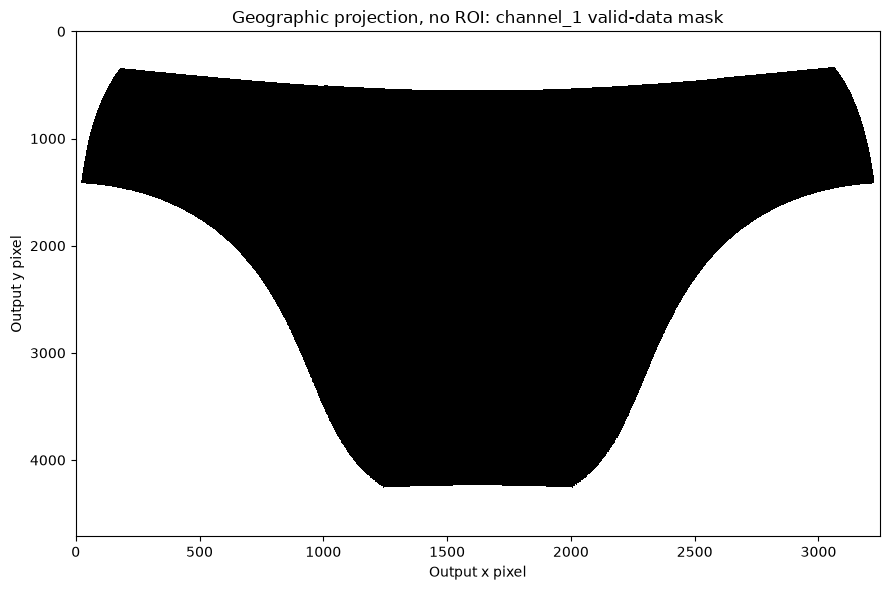

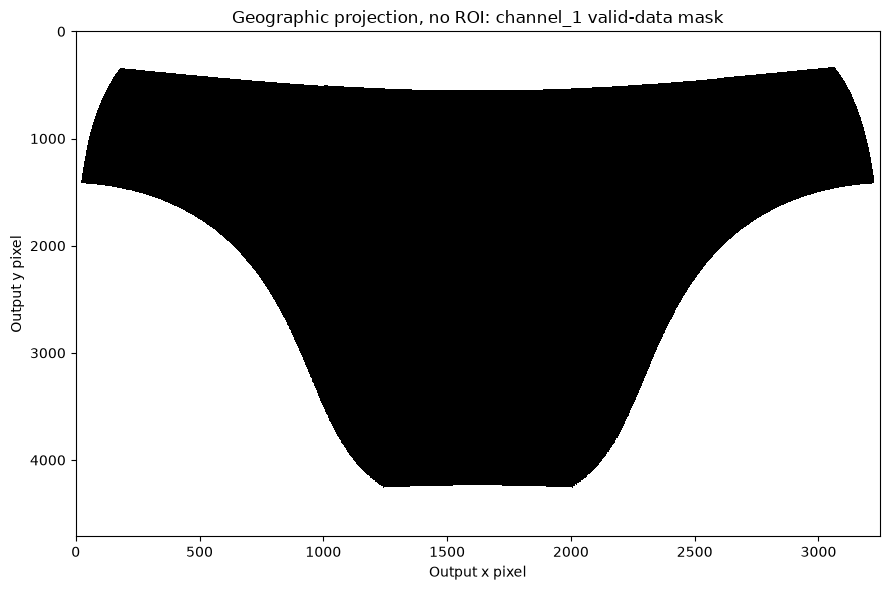

In [68]:
# Measure geographic/no-ROI coverage and show the valid-pixel mask.
import io
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

projection_no_roi_archives = sorted(JAN19_PROJECTION_NO_ROI_DIRECTORY.glob("HRSEVIRI_*.zip"))
if len(projection_no_roi_archives) != 1:
    raise FileNotFoundError(
        f"Expected one geographic/no-ROI ZIP, found {projection_no_roi_archives}"
    )
with zipfile.ZipFile(projection_no_roi_archives[0]) as archive:
    nc_members = [name for name in archive.namelist() if name.lower().endswith((".nc", ".nc4"))]
    if len(nc_members) != 1:
        raise ValueError(f"Expected one NetCDF member, found {nc_members}")
    with xr.open_dataset(io.BytesIO(archive.read(nc_members[0])), engine="h5netcdf") as ds:
        if "channel_1" not in ds:
            raise KeyError("Expected channel_1 in projected NetCDF output.")
        projected_values = ds["channel_1"].values.copy()
        projected_fill_text = ds.attrs.get("ch01_cal")
        projected_fill = float(projected_fill_text.split()[0]) if projected_fill_text else float(ds["channel_1"].attrs.get("_FillValue", np.nan))
        projected_valid = np.isfinite(projected_values)
        if np.isfinite(projected_fill):
            projected_valid &= ~np.isclose(projected_values, projected_fill, atol=1e-6)
        print(f"Output: {projection_no_roi_archives[0].name}")
        print(f"Dimensions: {dict(ds.sizes)}; variables: {list(ds.data_vars)}")
        print("Projection/ROI metadata:", {
            key: ds.attrs.get(key) for key in
            ("EPCT_projection", "EPCT_roi", "EPCT_geospatial_lat_min", "EPCT_geospatial_lat_max")
        })
        print(f"Coordinates: {list(ds.coords)}; overall valid fraction={projected_valid.mean():.1%}")
        lat_coord = ds.coords.get("lat")
        if lat_coord is not None and lat_coord.ndim == 1 and lat_coord.size == projected_valid.shape[0]:
            projected_lat = lat_coord.values
            print(f"Latitude grid: {projected_lat.min():.3f} to {projected_lat.max():.3f}°N")
            for lower, upper in [(49.7, 54.0), (54.0, 57.0), (57.0, 59.0), (59.0, 61.2)]:
                rows = (projected_lat >= lower) & (projected_lat < upper)
                if np.any(rows):
                    print(f"{lower:.1f}–{upper:.1f}°N valid: {projected_valid[rows].mean():.1%}")
        elif "y" in ds.coords:
            print("No 1-D latitude coordinate is available; the plotted mask uses output y/x pixels.")

fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(projected_valid, origin="upper", interpolation="nearest", cmap="gray_r", vmin=0, vmax=1, aspect="auto")
ax.set_title("Geographic projection, no ROI: channel_1 valid-data mask")
ax.set_xlabel("Output x pixel")
ax.set_ylabel("Output y pixel")
fig.tight_layout()
fig


### Result and working local reprojection path

The geographic/no-ROI Data Tailor product also has no valid pixels north of 57°N. This rules out the ROI as the cause and isolates the failure to Data Tailor's geographic projection path for this RSS scan. The original native scan and Data Tailor's no-projection NetCDF conversion retain the source data.

A local Satpy/Pyresample check on the same native file and same 270 × 288 WGS84 grid retains 99.9% valid pixels in every channel, with 100% coverage in the 57–61.2°N bands. The next cell saves those calibrated channels and plots Satpy's natural-colour composite. This provides a working Step 1 result while the Data Tailor projection issue remains isolated.


channel_1 (VIS006): 99.92% valid; latitude bands 49.7–54 / 54–57 / 57–59 / 59–61.2°N = 99.8%, 100.0%, 100.0%, 100.0%
channel_2 (VIS008): 99.92% valid; latitude bands 49.7–54 / 54–57 / 57–59 / 59–61.2°N = 99.8%, 100.0%, 100.0%, 100.0%
channel_3 (IR_016): 99.92% valid; latitude bands 49.7–54 / 54–57 / 57–59 / 59–61.2°N = 99.8%, 100.0%, 100.0%, 100.0%
channel_4 (IR_039): 99.92% valid; latitude bands 49.7–54 / 54–57 / 57–59 / 59–61.2°N = 99.8%, 100.0%, 100.0%, 100.0%
channel_5 (WV_062): 99.92% valid; latitude bands 49.7–54 / 54–57 / 57–59 / 59–61.2°N = 99.8%, 100.0%, 100.0%, 100.0%
channel_6 (WV_073): 99.92% valid; latitude bands 49.7–54 / 54–57 / 57–59 / 59–61.2°N = 99.8%, 100.0%, 100.0%, 100.0%
channel_7 (IR_087): 99.92% valid; latitude bands 49.7–54 / 54–57 / 57–59 / 59–61.2°N = 99.8%, 100.0%, 100.0%, 100.0%
channel_8 (IR_097): 99.92% valid; latitude bands 49.7–54 / 54–57 / 57–59 / 59–61.2°N = 99.8%, 100.0%, 100.0%, 100.0%
channel_9 (IR_108): 99.92% valid; latitude bands 49.7–54 / 54–57

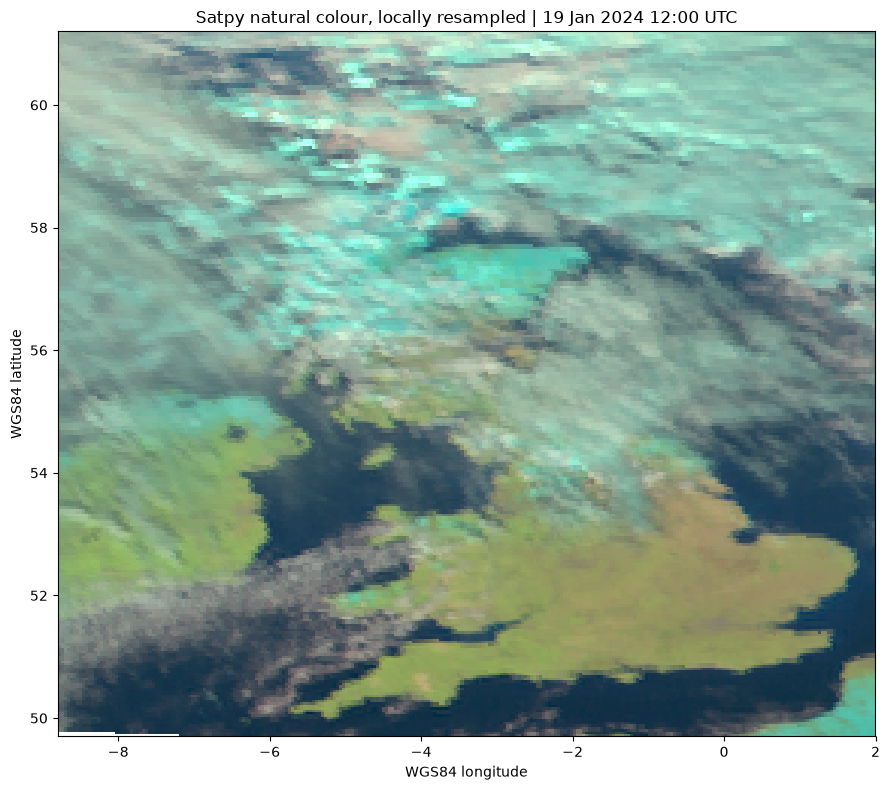

In [70]:
# Locally calibrate and reproject the native RSS product with Satpy/Pyresample.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from pyresample.geometry import AreaDefinition
from satpy import Scene
from satpy.enhancements.enhancer import get_enhanced_image

JAN19_NATIVE_DIRECTORY = JAN19_OUTPUT_DIRECTORY / "original_native_product"
local_native_files = list(JAN19_NATIVE_DIRECTORY.glob("*20240119120416*.nat"))
if len(local_native_files) != 1:
    raise FileNotFoundError(
        f"Expected one original Jan 19 12:00 .nat file, found: {local_native_files}"
    )
local_native_file = local_native_files[0]

# Data Tailor's output grid was 270 x 288 over this WGS84 extent.
LOCAL_GB_WIDTH = 270
LOCAL_GB_HEIGHT = 288
LOCAL_GB_EXTENT = (-8.8, 49.7, 2.0, 61.2)  # west, south, east, north
LOCAL_SATPY_DIRECTORY = JAN19_OUTPUT_DIRECTORY / "local_satpy_diagnostic"
LOCAL_SATPY_DIRECTORY.mkdir(parents=True, exist_ok=True)
LOCAL_SATPY_NETCDF = LOCAL_SATPY_DIRECTORY / "SEVIRI_RSS_20240119T120008Z_GB_local_satpy.nc"
LOCAL_SATPY_RGB = LOCAL_SATPY_DIRECTORY / "SEVIRI_RSS_20240119T120008Z_GB_local_satpy_rgb.png"

CHANNEL_MAP = {
    "channel_1": "VIS006", "channel_2": "VIS008", "channel_3": "IR_016",
    "channel_4": "IR_039", "channel_5": "WV_062", "channel_6": "WV_073",
    "channel_7": "IR_087", "channel_8": "IR_097", "channel_9": "IR_108",
    "channel_10": "IR_120", "channel_11": "IR_134",
}
local_scene = Scene(
    filenames=[str(local_native_file)], reader="seviri_l1b_native"
)
local_scene.load(["natural_color", *CHANNEL_MAP.values()], upper_right_corner="NE")
local_area = AreaDefinition(
    "gb_roi", "GB geographic grid", "EPSG:4326", "EPSG:4326",
    LOCAL_GB_WIDTH, LOCAL_GB_HEIGHT, LOCAL_GB_EXTENT,
)
local_resampled_scene = local_scene.resample(local_area, resampler="nearest")

# The output array is north-to-south in y, so latitude centers are descending.
west, south, east, north = LOCAL_GB_EXTENT
local_lon = west + (np.arange(LOCAL_GB_WIDTH) + 0.5) * ((east - west) / LOCAL_GB_WIDTH)
local_lat = north - (np.arange(LOCAL_GB_HEIGHT) + 0.5) * ((north - south) / LOCAL_GB_HEIGHT)
local_data_vars = {}
for output_name, satpy_name in CHANNEL_MAP.items():
    channel_data = local_resampled_scene[satpy_name]
    channel_values = np.asarray(channel_data.values, dtype=np.float32)
    local_data_vars[output_name] = (("y", "x"), channel_values, {
        "long_name": satpy_name,
        "units": str(channel_data.attrs.get("units", "")),
        "calibration": str(channel_data.attrs.get("calibration", "")),
        "grid_mapping": "crs",
    })
    valid = np.isfinite(channel_values)
    band_coverage = []
    for lower, upper in [(49.7, 54.0), (54.0, 57.0), (57.0, 59.0), (59.0, 61.2)]:
        rows = (local_lat >= lower) & (local_lat < upper)
        band_coverage.append(valid[rows].mean())
    print(
        f"{output_name} ({satpy_name}): {valid.mean():.2%} valid; "
        "latitude bands 49.7–54 / 54–57 / 57–59 / 59–61.2°N = "
        + ", ".join(f"{fraction:.1%}" for fraction in band_coverage)
    )

local_dataset = xr.Dataset(
    data_vars=local_data_vars,
    coords={
        "lat": ("y", local_lat, {"standard_name": "latitude", "units": "degrees_north"}),
        "lon": ("x", local_lon, {"standard_name": "longitude", "units": "degrees_east"}),
    },
)
local_dataset["crs"] = xr.DataArray(np.int32(0), attrs={
    "grid_mapping_name": "latitude_longitude",
    "longitude_of_prime_meridian": 0.0,
    "semi_major_axis": 6378137.0,
    "inverse_flattening": 298.257223563,
})
local_dataset.attrs.update({
    "title": "Meteosat SEVIRI RSS channels locally resampled with Satpy",
    "source_product": local_native_file.name,
    "start_time_utc": "2024-01-19T12:00:08.822Z",
    "end_time_utc": "2024-01-19T12:04:16.146Z",
    "spatial_crs": "EPSG:4326",
    "resampling": "nearest neighbor",
    "roi_west": west, "roi_south": south, "roi_east": east, "roi_north": north,
    "note": "Satpy seviri_l1b_native calibration and local Pyresample; no Data Tailor reprojection.",
    "attribution": "Contains modified EUMETSAT Meteosat data, 2024.",
})
local_encoding = {
    name: {"zlib": True, "complevel": 4, "_FillValue": -9999.0}
    for name in CHANNEL_MAP
}
local_dataset.to_netcdf(LOCAL_SATPY_NETCDF, engine="h5netcdf", encoding=local_encoding)
print(f"Saved calibrated 11-channel NetCDF: {LOCAL_SATPY_NETCDF}")

local_rgb = get_enhanced_image(local_resampled_scene["natural_color"]).data.clip(0, 1)
fig, ax = plt.subplots(figsize=(9, 8))
local_rgb.plot.imshow(ax=ax, rgb="bands")
ax.set_title("Satpy natural colour, locally resampled | 19 Jan 2024 12:00 UTC")
ax.set_xlabel("WGS84 longitude")
ax.set_ylabel("WGS84 latitude")
fig.tight_layout()
fig.savefig(LOCAL_SATPY_RGB, dpi=160)
print(f"Saved natural-colour figure: {LOCAL_SATPY_RGB}")
# fig
